In [25]:
import gc
import joblib

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap

import optuna
import optuna.visualization as vis
from optuna.integration import XGBoostPruningCallback

from scipy.cluster import hierarchy
from scipy.spatial.distance import squareform
from scipy.stats import spearmanr

from sklearn.compose import ColumnTransformer
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, make_scorer, r2_score, root_mean_squared_error
from sklearn.model_selection import (
    KFold,
    TimeSeriesSplit,
    cross_val_score,
    cross_validate,
    train_test_split
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MultiLabelBinarizer, OneHotEncoder, StandardScaler

import xgboost as xgb
from xgboost import XGBRegressor, plot_importance
from sklearn.inspection import PartialDependenceDisplay

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge

from sklearn.neural_network import MLPRegressor

<h2>Read-in Data</h2>

In [23]:
campd_type_dict = {
    'State': 'string',
    'Facility Name': 'string',
    'Facility ID': 'Int32',
    'Unit ID': 'string',
    'Hour': 'Int8',
    'Operating Time': 'float32',
    'Gross Load (MW)': 'float32',
    'Steam Load (1000 lb/hr)': 'float32',
    'SO2 Mass (lbs)': 'float64',
    'SO2 Mass Measure Indicator': 'string',
    'SO2 Rate (lbs/mmBtu)': 'float32',
    'SO2 Rate Measure Indicator': 'string',
    'CO2 Mass (short tons)': 'float32',
    'CO2 Mass Measure Indicator': 'string',
    'CO2 Rate (short tons/mmBtu)': 'float32',
    'CO2 Rate Measure Indicator': 'string',
    'Heat Input (mmBtu)': 'float64',
    'Heat Input Measure Indicator': 'string',
    'Primary Fuel Type': 'string',
    'Secondary Fuel Type': 'string',
    'Unit Type': 'string',
    'SO2 Controls': 'string',
    'Program Code': 'string',
    'Year': 'int16',
    'Source Category': 'string',
    'Latitude': 'float32',
    'Longitude': 'float32',
    'SO2 Phase': 'string',
    'Operating Status': 'string',
    'Max Hourly HI Rate (mmBtu/hr)': 'float32',
    'Associated Generators & Nameplate Capacity (MWe)': 'string',
    'Nameplate Capacity (MWe)': 'float32',
    'Month': 'Int8',
    'hourly_capacity_factor': 'float32',
    'hourly_ramping_factor': 'float32',
    'Nameplate Capacity (MW) - EIA': 'float32',
    'Summer Capacity (MW)': 'float32',
    'Winter Capacity (MW)': 'float32',
    'Minimum Load (MW)': 'float32',
    'Operating Year_min': 'float32',
    'Operating Year_max': 'float32',
    'Operating Year_mean': 'float32',
    'Planned Retirement Year': 'Int16',
    'unit_age_min': 'Int8',
    'unit_age_max': 'Int8',
    'unit_age_mean': 'float32',
    'Day': 'float32'
}

In [3]:
# Combine both operating and non-operating data into a full dataset for consistent time series analysis

# Data with operations
campd_ny_operating = pd.read_csv("NY/Hourly/Concatted File/ny_2019_2024_complete_cleaned.csv", dtype=campd_type_dict, date_format=["Date"])
# Data without operations
campd_ny_nonoperating = pd.read_csv("NY/Hourly/Concatted File/ny_2019_2024_complete_cleaned_NonOperating.csv", dtype=campd_type_dict, date_format=["Date"])

campd_ny = pd.concat([campd_ny_operating, campd_ny_nonoperating])
del campd_ny_nonoperating
del campd_ny_operating
gc.collect()

# create full datetime column (date + hour)
campd_ny["datetime"] = pd.to_datetime(campd_ny["Date"].astype(str) + ' ' + campd_ny["Hour"].astype(str).str.zfill(2) + ":00:00")

campd_ny.to_csv("NY/Hourly/Concatted File/ny_2019_2024_complete_cleaned_Full.csv", index=False)

In [4]:
campd_ny = pd.read_csv("NY/Hourly/Concatted File/ny_2019_2024_complete_cleaned_Full.csv", dtype=campd_type_dict)
campd_ny["Date"] = pd.to_datetime(campd_ny["Date"])
campd_ny["datetime"] = pd.to_datetime(campd_ny["datetime"])

<h2>Regression Models</h2>

<h3>Linear Regression</h3>

In [3]:
campd_df = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/CO2/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured", dtype=campd_type_dict)

In [4]:
df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

# features
num_features = ['Gross Load (MW)', 
                'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)']

unencoded_cat_features = ['Month', 'Hour', 'Day',
                    'Source Category', 
                    'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

In [6]:
navals = campd_df[num_features + unencoded_cat_features].isna().sum() / len(campd_df) * 100
navals[navals > 0]

# we test two data strategies, 
# 1 imputing with median 
# removing nan cols with excessive number of nan vals otherwise removing respective nan rows

Gross Load (MW)              6.013790
Latitude                    10.389658
Longitude                   10.389658
Nameplate Capacity (MWe)    10.389658
hourly_capacity_factor       6.989830
hourly_ramping_factor       16.404619
Summer Capacity (MW)        58.477659
Winter Capacity (MW)        58.477659
Minimum Load (MW)           58.477659
Temperature (F)              1.702535
dtype: float64

<h4>No Imputation, remove nan cols/rows</h4>

In [7]:
nan_cols = [
    'Gross Load (MW)',
    'Latitude',
    'Longitude',
    'Nameplate Capacity (MWe)',
    'hourly_capacity_factor',
    'hourly_ramping_factor',

    # we manually remove these cols altogether
    # 'Summer Capacity (MW)',
    # 'Winter Capacity (MW)',
    # 'Minimum Load (MW)',

    'Temperature (F)'
]

campd_df_cleaned = campd_df.dropna(subset=nan_cols)

print(f"Original shape: {campd_df.shape}, New shape: {campd_df_cleaned.shape}")
print(f"Change in total rows: {campd_df_cleaned.shape[0] - campd_df.shape[0]}")

Original shape: (3414203, 80), New shape: (2822490, 80)
Change in total rows: -591713


In [11]:
df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

# features
num_features = ['Gross Load (MW)', 
                'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                # 'Summer Capacity (MW)',
                # 'Winter Capacity (MW)', 
                # 'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)']

unencoded_cat_features = ['Month', 'Hour', 'Day',
                    'Source Category', 
                    'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_code_cols) #+ lag_cols # for passthrough of the manually one-hot encoded cols

target_variable = "CO2 Mass (short tons)"

# sort to put it in appropriate time series format
campd_df_cleaned = campd_df_cleaned.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df_cleaned[(campd_df_cleaned["Year"] < 2024) & (campd_df_cleaned["CO2 Mass (short tons)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df_cleaned[(campd_df_cleaned["Year"] < 2024) & (campd_df_cleaned["CO2 Mass (short tons)"].notna())][target_variable]  
X_test = campd_df_cleaned[(campd_df_cleaned["Year"] == 2024) & (campd_df_cleaned["CO2 Mass (short tons)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df_cleaned[(campd_df_cleaned["Year"] ==  2024) & (campd_df_cleaned["CO2 Mass (short tons)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', StandardScaler(), num_features),
        ('encoded', 'passthrough', encoded_cat_features) 
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

R^2 Score: 0.9978
Mean Squared Error (MSE): 7.0776
Root Mean Squared Error (RMSE): 2.6604
Normalized RMSE (by std): 0.0471


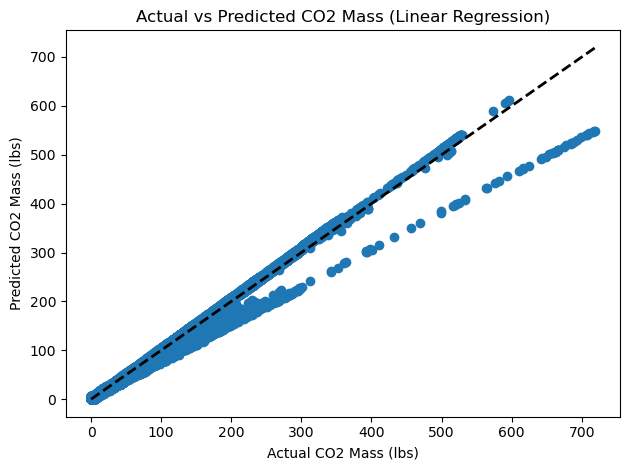

In [14]:
# default model (no lags, no unmeasured, with temps)

lr_model = Ridge(alpha=0.1)
lr_model.fit(X_train, y_train)

# Predict on test set
y_pred = lr_model.predict(X_test)

# Set negative predictions to 0
y_pred[y_pred < 0] = 0

# Evaluate performance
print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

# Plot actual vs predicted
plt.scatter(y_test, y_pred)
plt.xlabel("Actual CO2 Mass (lbs)")
plt.ylabel("Predicted CO2 Mass (lbs)")
plt.title("Actual vs Predicted CO2 Mass (Linear Regression)")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.tight_layout()
plt.show()

# struggles massively with higher emissions (imbalanced data)

R^2 Score: 0.9978
Mean Squared Error (MSE): 7.0780
Root Mean Squared Error (RMSE): 2.6605
Normalized RMSE (by std): 0.0471


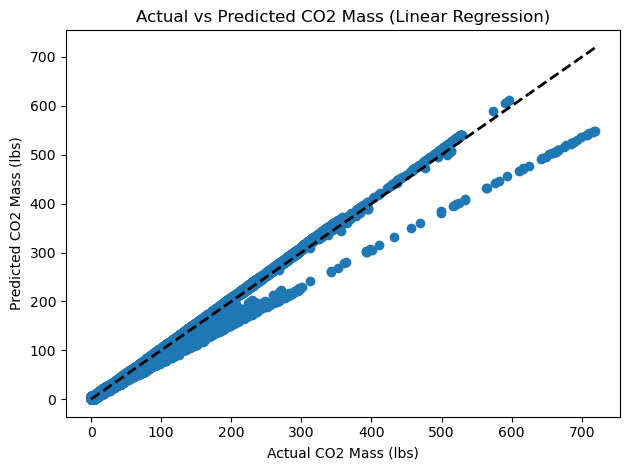

In [12]:
# default model (no lags, no unmeasured, with temps)

lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Predict on test set
y_pred = lr_model.predict(X_test)

# Set negative predictions to 0
y_pred[y_pred < 0] = 0

# Evaluate performance
print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

# Plot actual vs predicted
plt.scatter(y_test, y_pred)
plt.xlabel("Actual CO2 Mass (lbs)")
plt.ylabel("Predicted CO2 Mass (lbs)")
plt.title("Actual vs Predicted CO2 Mass (Linear Regression)")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.tight_layout()
plt.show()

# struggles massively with higher emissions (imbalanced data)

<h4>Median Imputation</h4>

In [18]:
df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

# features
num_features = ['Gross Load (MW)', 
                'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)']

unencoded_cat_features = ['Month', 'Hour', 'Day',
                    'Source Category', 
                    'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_code_cols) + lag_cols # for passthrough of the manually one-hot encoded cols

target_variable = "CO2 Mass (short tons)"

# sort to put it in appropriate time series format
campd_df = campd_df.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["CO2 Mass (short tons)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["CO2 Mass (short tons)"].notna())][target_variable]  
X_test = campd_df[(campd_df["Year"] == 2024) & (campd_df["CO2 Mass (short tons)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df[(campd_df["Year"] ==  2024) & (campd_df["CO2 Mass (short tons)"].notna())][target_variable]

# use simple imputer to fill nan values with median (necessary for linear regression)
num_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')), 
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', num_pipeline, num_features),
        ('encoded', 'passthrough', encoded_cat_features) 
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

R^2 Score: 0.9980
Mean Squared Error (MSE): 6.1736
Root Mean Squared Error (RMSE): 2.4847
Normalized RMSE (by std): 0.0448


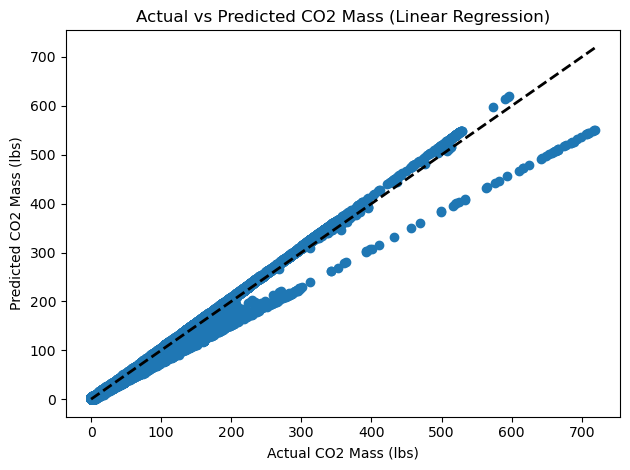

In [ ]:
# default model (no lags, no unmeasured, with temps)

lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Predict on test set
y_pred = lr_model.predict(X_test)

# Set negative predictions to 0
y_pred[y_pred < 0] = 0

# Evaluate performance
print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

# Plot actual vs predicted
plt.scatter(y_test, y_pred)
plt.xlabel("Actual CO2 Mass (lbs)")
plt.ylabel("Predicted CO2 Mass (lbs)")
plt.title("Actual vs Predicted CO2 Mass (Linear Regression)")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.tight_layout()
plt.show()



R^2 Score: 0.9980
Mean Squared Error (MSE): 6.1747
Root Mean Squared Error (RMSE): 2.4849
Normalized RMSE (by std): 0.0448


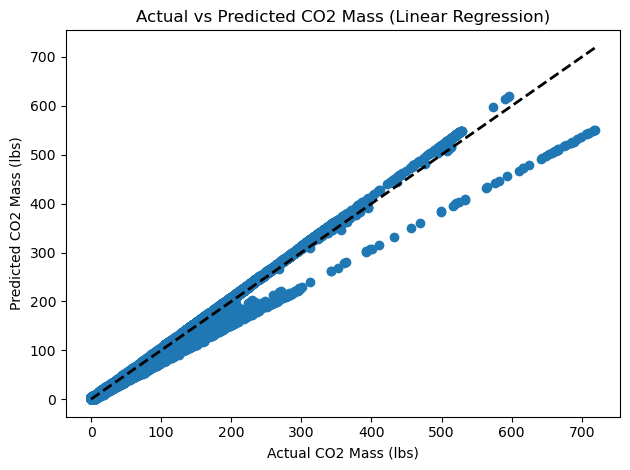

In [17]:
# default model (no lags, no unmeasured, with temps)

lr_model = Ridge(alpha=0.1)
lr_model.fit(X_train, y_train)

# Predict on test set
y_pred = lr_model.predict(X_test)

# Set negative predictions to 0
y_pred[y_pred < 0] = 0

# Evaluate performance
print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

# Plot actual vs predicted
plt.scatter(y_test, y_pred)
plt.xlabel("Actual CO2 Mass (lbs)")
plt.ylabel("Predicted CO2 Mass (lbs)")
plt.title("Actual vs Predicted CO2 Mass (Linear Regression)")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.tight_layout()
plt.show()



<h4>With Lags</h4>

In [19]:
# some lag values are nan and cannot be imputed -> need to drop
X_train = X_train.dropna(axis=0, how='any')  # drop rows with any NaN values
y_train = y_train[X_train.index]  # align y_train with X_train after dropping NaN rows

R^2 Score: 0.9976
Mean Squared Error (MSE): 7.3966
Root Mean Squared Error (RMSE): 2.7197
Normalized RMSE (by std): 0.0490


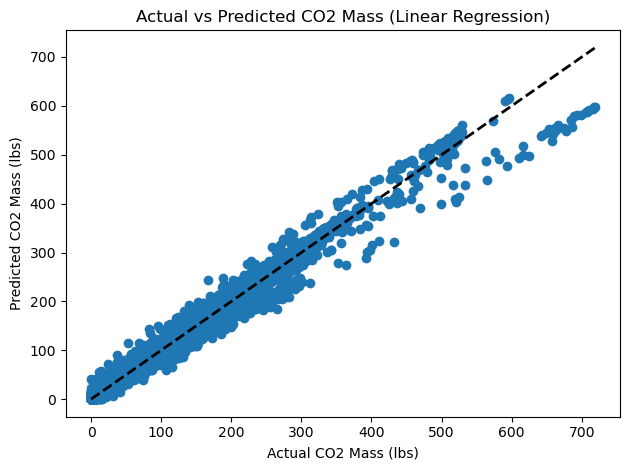

In [20]:
# default model (with lags, no unmeasured, with temps)

lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Predict on test set
y_pred = lr_model.predict(X_test)

# Set negative predictions to 0
y_pred[y_pred < 0] = 0

# Evaluate performance
print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

# Plot actual vs predicted
plt.scatter(y_test, y_pred)
plt.xlabel("Actual CO2 Mass (lbs)")
plt.ylabel("Predicted CO2 Mass (lbs)")
plt.title("Actual vs Predicted CO2 Mass (Linear Regression)")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.tight_layout()
plt.show()



R^2 Score: 0.9976
Mean Squared Error (MSE): 7.3966
Root Mean Squared Error (RMSE): 2.7197
Normalized RMSE (by std): 0.0490


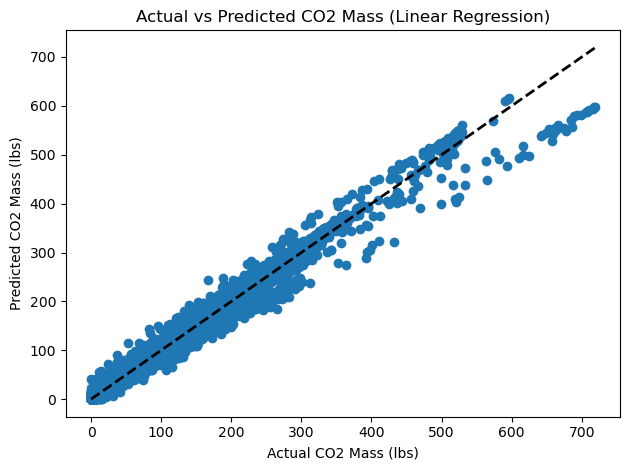

In [ ]:
# default model (with lags, no unmeasured, with temps)

lr_model = Ridge(alpha=0.1)
lr_model.fit(X_train, y_train)

# Predict on test set
y_pred = lr_model.predict(X_test)

# Set negative predictions to 0
y_pred[y_pred < 0] = 0

# Evaluate performance
print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

# Plot actual vs predicted
plt.scatter(y_test, y_pred)
plt.xlabel("Actual CO2 Mass (lbs)")
plt.ylabel("Predicted CO2 Mass (lbs)")
plt.title("Actual vs Predicted CO2 Mass (Linear Regression)")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.tight_layout()
plt.show()



<h3>MLP</h3>

In [26]:
campd_df = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/CO2/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured", dtype=campd_type_dict)

In [27]:
navals = campd_df[num_features + encoded_cat_features + unencoded_cat_features].isna().sum() / len(campd_df) * 100
navals[navals > 0]

# we test two data strategies, 
# 1 imputing with median 
# removing nan cols with excessive number of nan vals otherwise removing respective nan rows

Gross Load (MW)              6.013790
Latitude                    10.389658
Longitude                   10.389658
Nameplate Capacity (MWe)    10.389658
hourly_capacity_factor       6.989830
hourly_ramping_factor       16.404619
Summer Capacity (MW)        58.477659
Winter Capacity (MW)        58.477659
Minimum Load (MW)           58.477659
Temperature (F)              1.702535
lag_1_hour                   0.000088
lag_2_hours                  0.000176
lag_1_day                    0.001816
lag_2_days                   0.005067
lag_1_week                   0.018306
lag_1_month                  0.086638
lag_1_year                   2.308826
dtype: float64

<h4>No Imputation, remove nan cols/rows</h4>

In [28]:
nan_cols = [
    'Gross Load (MW)',
    'Latitude',
    'Longitude',
    'Nameplate Capacity (MWe)',
    'hourly_capacity_factor',
    'hourly_ramping_factor',

    # we manually remove these cols altogether
    # 'Summer Capacity (MW)',
    # 'Winter Capacity (MW)',
    # 'Minimum Load (MW)',

    'Temperature (F)'
]

campd_df_cleaned = campd_df.dropna(subset=nan_cols)

print(f"Original shape: {campd_df.shape}, New shape: {campd_df_cleaned.shape}")
print(f"Change in total rows: {campd_df_cleaned.shape[0] - campd_df.shape[0]}")

Original shape: (3414203, 80), New shape: (2822490, 80)
Change in total rows: -591713


In [29]:
df_control_cols = ['Ammonia Injection', 'Combustion Modification/Fuel Reburning',
       'Dry Low NOx Burners',
       'Low NOx Burner Technology (Dry Bottom only)',
       'Low NOx Burner Technology w/ Closed-coupled OFA',
       'Low NOx Burner Technology w/ Closed-coupled/Separated OFA',
       'Low NOx Burner Technology w/ Overfire Air',
       'Low NOx Burner Technology w/ Separated OFA', 'Nothing', 'Other',
       'Overfire Air', 'Selective Catalytic Reduction',
       'Selective Non-catalytic Reduction', 'Steam Injection',
       'Water Injection', 'Water Injection (Began Jul 01, 2022)']
df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

# features
num_features = ['Gross Load (MW)', 
                'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 
                'hourly_capacity_factor',
                'hourly_ramping_factor',
                # 'Summer Capacity (MW)',
                # 'Winter Capacity (MW)', 
                # 'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)']

unencoded_cat_features = ['Month', 'Hour', 'Day',
                    'Source Category', 
                    'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_code_cols) #+ lag_cols # for passthrough of the manually one-hot encoded cols

target_variable = "CO2 Mass (short tons)"

# sort to put it in appropriate time series format
campd_df_cleaned = campd_df_cleaned.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df_cleaned[(campd_df_cleaned["Year"] < 2024) & (campd_df_cleaned["CO2 Mass (short tons)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df_cleaned[(campd_df_cleaned["Year"] < 2024) & (campd_df_cleaned["CO2 Mass (short tons)"].notna())][target_variable]  
X_test = campd_df_cleaned[(campd_df_cleaned["Year"] == 2024) & (campd_df_cleaned["CO2 Mass (short tons)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df_cleaned[(campd_df_cleaned["Year"] ==  2024) & (campd_df_cleaned["CO2 Mass (short tons)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', StandardScaler(), num_features),
        ('encoded', 'passthrough', encoded_cat_features)  # add the pre-encoded features (CO2 Controls)
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [30]:
# mlp struggles with large datasets, so we downsample the training data to 20%
X_sampled, y_sampled = (
    X_train.sample(frac=0.2, random_state=42),
    y_train.loc[X_train.sample(frac=0.2, random_state=42).index]
)

In [31]:
X_sampled.shape

(472586, 108)

In [ ]:
mlp_default_model = MLPRegressor(random_state=42)
mlp_default_model.fit(X_sampled, y_sampled)

# using the sampled training data, this took 8mins

In [34]:
joblib.dump(mlp_default_model, "NY/Hourly/Concatted File/Modeling/MLP/CO2/Trained Models/mlp_default_model_ny_no_lags_no_unmeasured_with_temps_NO_MEDIAN.json", compress=True)

['NY/Hourly/Concatted File/Modeling/MLP/CO2/Trained Models/mlp_default_model_ny_no_lags_no_unmeasured_with_temps_NO_MEDIAN.json']

In [35]:
y_pred = mlp_default_model.predict(X_test)

R^2 Score: 0.9933
Mean Squared Error (MSE): 21.3258
Root Mean Squared Error (RMSE): 4.6180
Normalized RMSE (by std): 0.0817


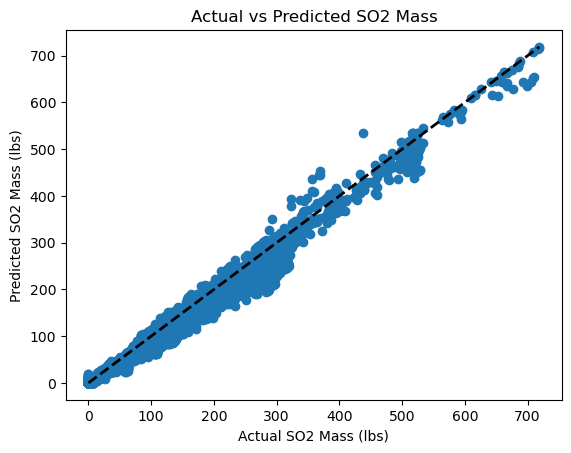

In [36]:
# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual SO2 Mass (lbs)")
plt.ylabel("Predicted SO2 Mass (lbs)")
plt.title("Actual vs Predicted SO2 Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

<h4>Median Imputation</h4>

In [37]:
df_control_cols = ['Ammonia Injection', 'Combustion Modification/Fuel Reburning',
       'Dry Low NOx Burners',
       'Low NOx Burner Technology (Dry Bottom only)',
       'Low NOx Burner Technology w/ Closed-coupled OFA',
       'Low NOx Burner Technology w/ Closed-coupled/Separated OFA',
       'Low NOx Burner Technology w/ Overfire Air',
       'Low NOx Burner Technology w/ Separated OFA', 'Nothing', 'Other',
       'Overfire Air', 'Selective Catalytic Reduction',
       'Selective Non-catalytic Reduction', 'Steam Injection',
       'Water Injection', 'Water Injection (Began Jul 01, 2022)']
df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

# features
num_features = ['Gross Load (MW)', 
                'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 
                'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)']

unencoded_cat_features = ['Month', 'Hour', 'Day',
                    'Source Category', 
                    'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_code_cols) #+ lag_cols # for passthrough of the manually one-hot encoded cols

target_variable = "CO2 Mass (short tons)"

# sort to put it in appropriate time series format
campd_df = campd_df.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["CO2 Mass (short tons)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["CO2 Mass (short tons)"].notna())][target_variable]  
X_test = campd_df[(campd_df["Year"] == 2024) & (campd_df["CO2 Mass (short tons)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df[(campd_df["Year"] ==  2024) & (campd_df["CO2 Mass (short tons)"].notna())][target_variable]

numeric_imputer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', numeric_imputer, num_features),
        ('encoded', 'passthrough', encoded_cat_features)  # add the pre-encoded features (CO2 Controls)
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [38]:
# mlp struggles with large datasets, so we downsample the training data to 20%
X_sampled, y_sampled = (
    X_train.sample(frac=0.2, random_state=42),
    y_train.loc[X_train.sample(frac=0.2, random_state=42).index]
)

In [39]:
X_sampled.shape

(572927, 115)

In [ ]:
mlp_default_model = MLPRegressor(random_state=42)
mlp_default_model.fit(X_sampled, y_sampled)

# using the sampled training data, this took 14mins

In [41]:
joblib.dump(mlp_default_model, "NY/Hourly/Concatted File/Modeling/MLP/CO2/Trained Models/mlp_default_model_ny_no_lags_no_unmeasured_with_temps.json", compress=True)

['NY/Hourly/Concatted File/Modeling/MLP/CO2/Trained Models/mlp_default_model_ny_no_lags_no_unmeasured_with_temps.json']

In [42]:
y_pred = mlp_default_model.predict(X_test)

R^2 Score: 0.9950
Mean Squared Error (MSE): 15.2660
Root Mean Squared Error (RMSE): 3.9072
Normalized RMSE (by std): 0.0704


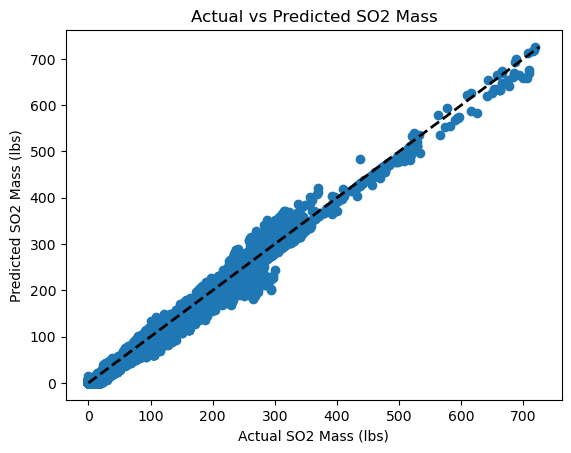

In [43]:
# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual SO2 Mass (lbs)")
plt.ylabel("Predicted SO2 Mass (lbs)")
plt.title("Actual vs Predicted SO2 Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

<h4>With Lags</h4>

In [44]:
df_control_cols = ['Ammonia Injection', 'Combustion Modification/Fuel Reburning',
       'Dry Low NOx Burners',
       'Low NOx Burner Technology (Dry Bottom only)',
       'Low NOx Burner Technology w/ Closed-coupled OFA',
       'Low NOx Burner Technology w/ Closed-coupled/Separated OFA',
       'Low NOx Burner Technology w/ Overfire Air',
       'Low NOx Burner Technology w/ Separated OFA', 'Nothing', 'Other',
       'Overfire Air', 'Selective Catalytic Reduction',
       'Selective Non-catalytic Reduction', 'Steam Injection',
       'Water Injection', 'Water Injection (Began Jul 01, 2022)']
df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

# features
num_features = ['Gross Load (MW)', 
                'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 
                'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)']

unencoded_cat_features = ['Month', 'Hour', 'Day',
                    'Source Category', 
                    'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_code_cols) + lag_cols # for passthrough of the manually one-hot encoded cols

target_variable = "CO2 Mass (short tons)"

# sort to put it in appropriate time series format
campd_df = campd_df.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["CO2 Mass (short tons)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["CO2 Mass (short tons)"].notna())][target_variable]  
X_test = campd_df[(campd_df["Year"] == 2024) & (campd_df["CO2 Mass (short tons)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df[(campd_df["Year"] ==  2024) & (campd_df["CO2 Mass (short tons)"].notna())][target_variable]

numeric_imputer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', numeric_imputer, num_features),
        ('encoded', 'passthrough', encoded_cat_features)  # add the pre-encoded features (CO2 Controls)
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [45]:
# mlp struggles with large datasets, so we downsample the training data to 20%
X_sampled, y_sampled = (
    X_train.sample(frac=0.2, random_state=42),
    y_train.loc[X_train.sample(frac=0.2, random_state=42).index]
)

In [46]:
X_sampled.shape

(572927, 122)

In [48]:
# remove time lags nans
X_sampled = X_sampled.dropna()
y_sampled = y_sampled[X_sampled.index]

In [ ]:
mlp_default_model = MLPRegressor(random_state=42)
mlp_default_model.fit(X_sampled, y_sampled)

# using the sampled training data, this took 10mins

MLPRegressor(random_state=42)

In [50]:
y_pred = mlp_default_model.predict(X_test)

R^2 Score: 0.9996
Mean Squared Error (MSE): 1.3434
Root Mean Squared Error (RMSE): 1.1591
Normalized RMSE (by std): 0.0209


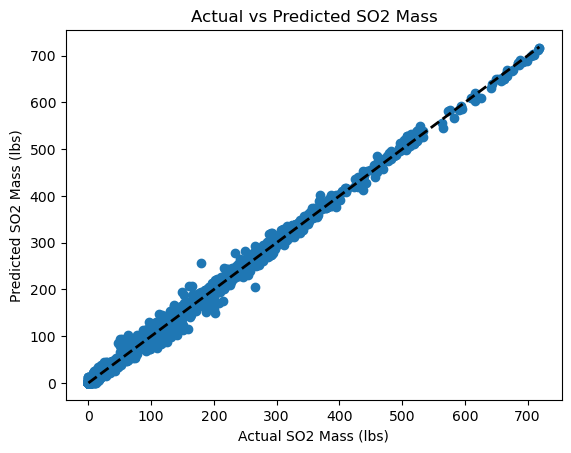

In [51]:
# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual SO2 Mass (lbs)")
plt.ylabel("Predicted SO2 Mass (lbs)")
plt.title("Actual vs Predicted SO2 Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

<h3>Random Forest</h3>

In [ ]:
# default params are:
# n_estimators=100, *, criterion='gini', max_depth=None, min_samples_split=2, 
# min_samples_leaf=1, min_weight_fraction_leaf=0.0, max_features='sqrt', 
# max_leaf_nodes=None, min_impurity_decrease=0.0, bootstrap=True, oob_score=False,
#  n_jobs=None, random_state=None, verbose=0, warm_start=False, class_weight=None, 
# ccp_alpha=0.0, max_samples=None, monotonic_cst=None

In [4]:
campd_df = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/CO2/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured", dtype=campd_type_dict)

In [5]:
df_control_cols = ['Ammonia Injection', 'Combustion Modification/Fuel Reburning',
       'Dry Low NOx Burners',
       'Low NOx Burner Technology (Dry Bottom only)',
       'Low NOx Burner Technology w/ Closed-coupled OFA',
       'Low NOx Burner Technology w/ Closed-coupled/Separated OFA',
       'Low NOx Burner Technology w/ Overfire Air',
       'Low NOx Burner Technology w/ Separated OFA', 'Nothing', 'Other',
       'Overfire Air', 'Selective Catalytic Reduction',
       'Selective Non-catalytic Reduction', 'Steam Injection',
       'Water Injection', 'Water Injection (Began Jul 01, 2022)']
df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

# features
num_features = ['Gross Load (MW)', 
                'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)']

unencoded_cat_features = ['Month', 'Hour', 'Day',
                    'Source Category', 
                    'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_code_cols) #+ lag_cols # for passthrough of the manually one-hot encoded cols

target_variable = "CO2 Mass (short tons)"

# sort to put it in appropriate time series format
campd_df = campd_df.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["CO2 Mass (short tons)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["CO2 Mass (short tons)"].notna())][target_variable]  
X_test = campd_df[(campd_df["Year"] == 2024) & (campd_df["CO2 Mass (short tons)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df[(campd_df["Year"] ==  2024) & (campd_df["CO2 Mass (short tons)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', 'passthrough', num_features),
        ('encoded', 'passthrough', encoded_cat_features)  # add the pre-encoded features (CO2 Controls)
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [6]:
# rf struggles with large datasets, so we downsample the training data to 20%
X_sampled, y_sampled = (
    X_train.sample(frac=0.2, random_state=42),
    y_train.loc[X_train.sample(frac=0.2, random_state=42).index]
)

In [7]:
X_sampled.shape

(572927, 115)

In [8]:
# still takes approx. 3 mins to compute

rf_model_no_lags = RandomForestRegressor(random_state=42, n_jobs=-1) # max_depth=5 without max depth it takes very long

# Train Random Forest model with default parameters
rf_model_no_lags.fit(X_sampled, y_sampled.values.ravel())

RandomForestRegressor(n_jobs=-1, random_state=42)

In [9]:
joblib.dump(rf_model_no_lags, "NY/Hourly/Concatted File/Modeling/RF/CO2/Trained Models/rf_default_model_ny_no_lags_no_unmeasured_with_temps.json")

['NY/Hourly/Concatted File/Modeling/RF/CO2/Trained Models/rf_default_model_ny_no_lags_no_unmeasured_with_temps.json']

In [57]:
rf_model_no_lags = joblib.load("NY/Hourly/Concatted File/Modeling/RF/CO2/Trained Models/rf_default_model_ny_no_lags_no_unmeasured_with_temps.json")

R^2 Score: 0.9993
Mean Squared Error (MSE): 2.0843
Root Mean Squared Error (RMSE): 1.4437
Normalized RMSE (by std): 0.0260


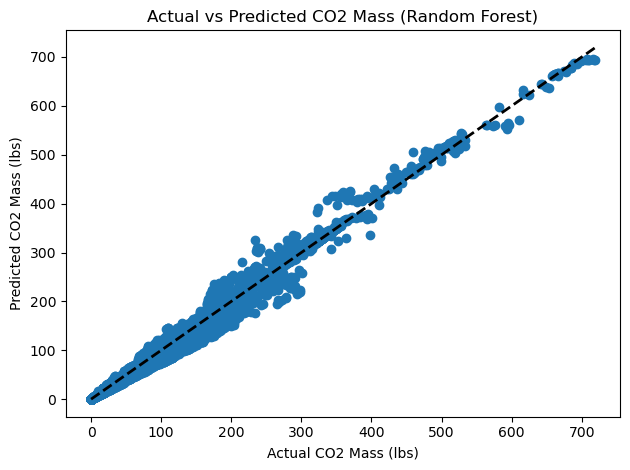

In [10]:
# default model (no lags, no unmeasured data, with temps)

y_pred = rf_model_no_lags.predict(X_test)

# Set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual CO2 Mass (lbs)")
plt.ylabel("Predicted CO2 Mass (lbs)")
plt.title("Actual vs Predicted CO2 Mass (Random Forest)")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.tight_layout()
plt.show()

In [ ]:
# even with downsampling takes approx. 4 mins to compute

rf_model_with_lags = RandomForestRegressor(random_state=42, n_jobs=-1) # max_depth=5 without max depth it takes very long

rf_model_with_lags.fit(X_sampled, y_sampled.values.ravel())

joblib.dump(rf_model_with_lags, "NY/Hourly/Concatted File/Modeling/RF/CO2/Trained Models/rf_default_model_ny_with_lags_no_unmeasured_with_temps.json")

['NY/Hourly/Concatted File/Modeling/RF/CO2/Trained Models/rf_default_model_ny_with_lags_no_unmeasured_with_temps.json']

In [ ]:
rf_model_with_lags = joblib.load("NY/Hourly/Concatted File/Modeling/RF/CO2/Trained Models/rf_default_model_ny_with_lags_with_unmeasured_with_temps.json")

R^2 Score: 0.9996
Mean Squared Error (MSE): 1.2924
Root Mean Squared Error (RMSE): 1.1368
Normalized RMSE (by std): 0.0205


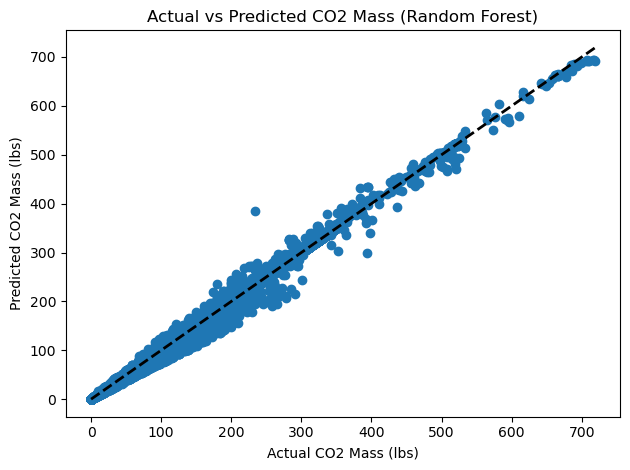

In [ ]:
# default model (with lags, no unmeasured data, with temps)

y_pred = rf_model_with_lags.predict(X_test)

# Set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

# Evaluate performance
print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

# Plot actual vs predicted
plt.scatter(y_test, y_pred)
plt.xlabel("Actual CO2 Mass (lbs)")
plt.ylabel("Predicted CO2 Mass (lbs)")
plt.title("Actual vs Predicted CO2 Mass (Random Forest)")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.tight_layout()
plt.show()

<h3>XGBoost</h3>

<h5>Preprocessing Methods</h5>

In [5]:
# manually create lag columns
def create_lag_features_per_group(group, emission_type):
    group["lag_1_hour"] = group[emission_type].shift(1)  # 1 hour lag
    group["lag_2_hours"] = group[emission_type].shift(2)  # 2 hours lag
    group["lag_1_day"] = group[emission_type].shift(24)  # 1 day lag (24 hours)
    group["lag_2_days"] = group[emission_type].shift(48)  # 2 days lag (48 hours)
    group["lag_1_week"] = group[emission_type].shift(24 * 7)  # 1 week lag (168 hours)
    group["lag_1_month"] = group[emission_type].shift(24 * 30)  # ~1 month lag (720 hours)
    group["lag_1_year"] = group[emission_type].shift(24 * 365)  # ~1 year lag (8760 hours)
    return group

def preprocess_lag_features(df, previous_year_df, emission_type):
    cutoff_year = df["Year"].min()

    # Combine the two dfs
    df = pd.concat([df, previous_year_df])

    # Set datetime as the index for time-series operations
    df = df.set_index("datetime")

    # Sort the DataFrame by the datetime index to ensure proper alignment
    df = df.sort_index()

    # Sort the DataFrame by Facility ID, Unit ID, and datetime to ensure proper alignment
    df = df.sort_values(by=["Facility ID", "Unit ID", "datetime"])

    # Apply the lag feature function to each group
    df = df.groupby(["Facility ID", "Unit ID"], group_keys=False).apply(
    create_lag_features_per_group, emission_type=emission_type)

    df = df.reset_index()

    # Filter out the previous year again
    df = df[df["Year"] >= cutoff_year]

    # ensure to add datetime back as normal column
    df["datetime"] = pd.to_datetime(df["Date"].astype(str) + ' ' + df["Hour"].astype(str).str.zfill(2) + ":00:00")


    return df


In [6]:
# manually one-hot encode Program Codes
def preprocess_program_codes(df):

    # Split the strings into lists
    program_lists = df['Program Code'].str.split(', ')

    mlb = MultiLabelBinarizer()
    program_dummies = pd.DataFrame(mlb.fit_transform(program_lists), 
                                columns=mlb.classes_, 
                                index=df.index)

    # Concatenate with original DataFrame or add to your features
    df = pd.concat([df, program_dummies], axis=1)

    return df, mlb.classes_


# campd_ny, ny_code_cols = preprocess_program_codes(campd_ny)
# ny_code_cols

<h5>Full Model Train and Test</h5>

<h6>Preprocessing</h6>

In [7]:
campd_ny["Day"] = campd_ny["datetime"].dt.day

In [8]:
# read in previous year to get according lags
campd_ny_2018 = pd.read_csv("NY/Hourly/Before 2019/emissions-hourly-2018-ny.csv", dtype=campd_type_dict, date_format=["Date"])
campd_ny_2018 = campd_ny_2018[["Facility ID", "Unit ID", "Date", "Hour", "CO2 Mass (short tons)"]]
campd_ny_2018["datetime"] = pd.to_datetime(campd_ny_2018["Date"].astype(str) + ' ' + campd_ny_2018["Hour"].astype(str).str.zfill(2) + ":00:00")
campd_ny_2018["CO2 Mass (short tons)"] = campd_ny_2018["CO2 Mass (short tons)"].fillna(0)

# compute lags
campd_df = preprocess_lag_features(campd_ny, campd_ny_2018, "CO2 Mass (short tons)")

C:\Users\marce\AppData\Local\Temp\ipykernel_38276\212535289.py:2: DtypeWarning: Columns (4,19,21,28,29,30) have mixed types. Specify dtype option on import or set low_memory=False.
  campd_ny_2018 = pd.read_csv("NY/Hourly/Before 2019/emissions-hourly-2018-ny.csv", dtype=campd_type_dict, date_format=["Date"])
C:\Users\marce\AppData\Local\Temp\ipykernel_38276\2313467750.py:28: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df = df.groupby(["Facility ID", "Unit ID"], group_keys=False).apply(
C:\Users\marce\AppData\Local\Temp\ipykernel_38276\2313467750.py:37: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent an

In [9]:
campd_df.to_csv("NY/Hourly/Concatted File/Modeling/XGB/CO2/ny_2019_2024_complete_cleaned_Full_with_CO2_lags.csv", index=False)

In [ ]:
campd_df = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/CO2/ny_2019_2024_complete_cleaned_Full_with_CO2_lags.csv", dtype=campd_type_dict)
campd_df["Date"] = pd.to_datetime(campd_df["Date"])
campd_df["datetime"] = pd.to_datetime(campd_df["datetime"])

In [10]:
# manually one-hot encode program codes
campd_df, df_code_cols = preprocess_program_codes(campd_df)

# manually sin/cos encode cyclical features hour, day, month
def encode_cyclical(df, col, max_val):
    df[f"{col}_sin"] = np.sin(2 * np.pi * df[col] / max_val)
    df[f"{col}_cos"] = np.cos(2 * np.pi * df[col] / max_val)
    col_names = [f"{col}_sin", f"{col}_cos"]
    return df, col_names
campd_df, hour_cols = encode_cyclical(campd_df, "Hour", 24) # Daily seasonality
campd_df, day_cols = encode_cyclical(campd_df, "Day", 7)  # Weekly seasonality
campd_df, month_cols = encode_cyclical(campd_df, "Month", 12) # Yearly seasonality
cyclical_cols = hour_cols + day_cols + month_cols

In [11]:
campd_df.to_csv("NY/Hourly/Concatted File/Modeling/XGB/CO2/ny_2019_2024_complete_cleaned_Full_manually_encoded", index=False)

In [ ]:
campd_df = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/CO2/ny_2019_2024_complete_cleaned_Full_manually_encoded", dtype=campd_type_dict)

In [12]:
# Randomly remove a fraction of rows where Operating Time is 0.
def downsample_zero_operating_time(df, frac_to_remove=0.9, random_state=42):
    # create dfs for those with and without operating time
    zero_op = df[df["Operating Time"] == 0]
    non_zero_op = df[df["Operating Time"] != 0]

    # remove sample of rows
    drop_sample = zero_op.sample(frac=frac_to_remove, random_state=random_state)
    kept_zero_op = zero_op.drop(index=drop_sample.index)
    df_downsampled = pd.concat([non_zero_op, kept_zero_op]).sort_index()

    return df_downsampled


In [13]:
campd_df.shape

(14028675, 80)

In [14]:
# Downsample 90% of the nonOperating data (should be fine since xgb does not require continuity unlike e. g. LSTM)
campd_df = downsample_zero_operating_time(campd_df)

In [15]:
campd_df.shape

(3563498, 80)

In [16]:
campd_df.to_csv("NY/Hourly/Concatted File/Modeling/XGB/CO2/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled", index=False)

In [ ]:
campd_df = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/CO2/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled", dtype=campd_type_dict)

In [17]:
campd_df["CO2 Mass Measure Indicator"].value_counts()

CO2 Mass Measure Indicator
Measured                   2251406
Nothing                    1162797
Measured and Substitute      76386
LME                          72482
Substitute                     427
Name: count, dtype: Int64

In [18]:
campd_df = campd_df[(campd_df["CO2 Mass Measure Indicator"] == "Measured") | (campd_df["CO2 Mass Measure Indicator"] == "Nothing")]
campd_df["CO2 Mass Measure Indicator"].value_counts()

CO2 Mass Measure Indicator
Measured    2251406
Nothing     1162797
Name: count, dtype: Int64

In [19]:
campd_df.to_csv("NY/Hourly/Concatted File/Modeling/XGB/CO2/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured", index=False)

In [3]:
campd_df = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/CO2/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured", dtype=campd_type_dict)

In [12]:
# https://www.ecfr.gov/current/title-40/chapter-I/subchapter-C/part-75/appendix-Appendix%20G%20to%20Part%2075
# Eq. G-4

# eq. G-4 is only meant for gas- and oil-fired units
natural_gas = ["Pipeline Natural Gas", 
                    "Natural Gas"]

oil = ["Diesel Oil","Residual Oil", "Other Oil"]


campd_df.loc[campd_df["Primary Fuel Type"].isin(natural_gas), "Calc CO2 emission rate (tons)"] = (44 * 1040 * campd_df["Heat Input (mmBtu)"] * (1 / 385)) / 2000

campd_df.loc[campd_df["Primary Fuel Type"].isin(oil), "Calc CO2 emission rate (tons)"] = (44 * 1420 * campd_df["Heat Input (mmBtu)"] * (1 / 385)) / 2000


In [8]:
df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

In [18]:
# features
num_features = ['Gross Load (MW)', 
                'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)',
                 "Calc CO2 emission rate (tons)"]

unencoded_cat_features = ['Month', 'Hour', 'Day',
                    'Source Category', 
                    'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_code_cols) #+ lag_cols # for passthrough of the manually one-hot encoded cols

target_variable = "CO2 Mass (short tons)"

# sort to put it in appropriate time series format
campd_df = campd_df.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["CO2 Mass (short tons)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["CO2 Mass (short tons)"].notna())][target_variable]  
X_test = campd_df[(campd_df["Year"] == 2024) & (campd_df["CO2 Mass (short tons)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df[(campd_df["Year"] ==  2024) & (campd_df["CO2 Mass (short tons)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', 'passthrough', num_features),
        ('encoded', 'passthrough', encoded_cat_features)  # add the pre-encoded features (CO2 Controls)
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan


ColumnTransformer(transformers=[('cat',
                                 OneHotEncoder(handle_unknown='ignore',
                                               sparse_output=False),
                                 ['Month', 'Hour', 'Day', 'Source Category',
                                  'Unit Type', 'Primary Fuel Type',
                                  'Secondary Fuel Type']),
                                ('num', 'passthrough',
                                 ['Gross Load (MW)', 'Heat Input (mmBtu)',
                                  'Latitude', 'Longitude',
                                  'Nameplate Capacity (MWe)',
                                  'hourly_capacity_factor',
                                  'hourly_ramping_factor',
                                  'Summer Capacity (MW)',
                                  'Winter Capacity (MW)', 'Minimum Load (MW)',
                                  'Year', 'Temperature (F)',
                                  'Calc CO2 emission rate (tons)']),
                                ('encoded', 'passthrough',
                                 ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3',
                                  'CSSO2G1', 'MATS', 'Missing', 'NSPS4T',
                                  'RGGI', 'SIPNOX'])])

In [22]:
X_train.to_csv("NY/Hourly/Concatted File/Modeling/XGB/CO2/X_train", index=False)
X_test.to_csv("NY/Hourly/Concatted File/Modeling/XGB/CO2/X_test", index=False)
y_train.to_csv("NY/Hourly/Concatted File/Modeling/XGB/CO2/y_train", index=False)
y_test.to_csv("NY/Hourly/Concatted File/Modeling/XGB/CO2/y_test", index=False)

In [ ]:
X_train = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/CO2/X_train", dtype=campd_type_dict)
X_test = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/CO2/X_test", dtype=campd_type_dict)

In [ ]:
y_train = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/CO2/y_train")
y_test = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/CO2/y_test")

In [19]:
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [24]:
X_train.to_csv("NY/Hourly/Concatted File/Modeling/XGB/CO2/X_train_processed", index=False)
X_test.to_csv("NY/Hourly/Concatted File/Modeling/XGB/CO2/X_test_processed", index=False)

In [4]:
X_train = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/CO2/X_train_processed", dtype=campd_type_dict)
X_test = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/CO2/X_test_processed", dtype=campd_type_dict)

In [20]:
dtrain = xgb.DMatrix(X_train, label=y_train)
dtest = xgb.DMatrix(X_test, label=y_test)

In [26]:
dtrain.save_binary("NY/Hourly/Concatted File/Modeling/XGB/CO2/dtrain_ny_full_2019_2023.buffer")
dtest.save_binary("NY/Hourly/Concatted File/Modeling/XGB/CO2/dtest_ny_full_2024.buffer")

In [13]:
dtrain = xgb.DMatrix("NY/Hourly/Concatted File/Modeling/XGB/CO2/dtrain_ny_full_2019_2023.buffer")
dtest = xgb.DMatrix("NY/Hourly/Concatted File/Modeling/XGB/CO2/dtest_ny_full_2024.buffer")

<h6>Using Default Parameters</h6>

In [12]:
# default parameters for comparison
default_params = {
    # "n_estimators": 100, # number of trees (larger value, more likely to overfit)
    # "max_depth":  6, # max depth of a tree (larger value, more complex, more likely to overfit)
    # "learning_rate": 0.5, # step size shrinkage eta (lower value, more conservative)
    # "subsample": 1, # random subset size of data to use for each tree (lower value, more conservative)
    # "colsample_bytree": 1, # random subset of features to consider for each tree (lower value, more conservative)
    # "gamma": 0, # min loss reduction to make a split (larger value, more conservative)
    # "reg_alpha": 0, # L1 regularization on weights (larger value, more conservative)
    # "reg_lambda": 1, # L2 regularization on weights (larger value, more conservative)
    # "min_child_weight": 1, # min sum of instance weight (hessian) needed in a child (larger value, more conservative)
    # "tree_method": "auto" # automatically chooses exact or approximation method based on data size

    # needed params for xgb.train
    "objective": "reg:squarederror",
    'eval_metric': 'rmse',
    #"device": "cuda", # use gpu (if unavailable, will use cpu)
    'seed': 42 # like random_state, but for xgb.train
}

In [28]:
# Time Series Split

n_splits = 5
tscv = TimeSeriesSplit(n_splits=n_splits)
best_iterations = []
rmse_scores = []
r2_scores = []

# iterate over each fold and assign the train and test values based on the indeces of the TimeSeriesSplit
for fold, (train_idx, test_idx) in enumerate(tscv.split(X_train)):
    current_X_train, current_X_test = X_train.iloc[train_idx], X_train.iloc[test_idx]
    current_y_train, current_y_test = y_train.iloc[train_idx], y_train.iloc[test_idx]
    
    current_dtrain = xgb.DMatrix(current_X_train, label=current_y_train)
    current_dtest = xgb.DMatrix(current_X_test, label=current_y_test)
    
    # train a model on the current training data and validate it on testing data. create models with up to 1000 boost round until validation shows no more progress (after 20 rounds)
    model = xgb.train(
        default_params,
        current_dtrain,
        num_boost_round=1000,
        early_stopping_rounds=20,
        evals=[(current_dtest, "validation")],
        verbose_eval=False # prevents printing at each boosting stage
    )
    
    # predict on validation for this fold and store the evaluation metric rmse
    y_pred = model.predict(current_dtest)
    rmse = root_mean_squared_error(current_y_test, y_pred)
    r2 = r2_score(current_y_test, y_pred)
    
    best_iterations.append(model.best_iteration)
    rmse_scores.append(rmse)
    r2_scores.append(r2)
    
    print(f"Fold {fold+1}: best_iteration={model.best_iteration}, RMSE={rmse:.4f}, R2={r2:.4f}")

# average best iteration across all folds
optimal_rounds = int(np.mean(best_iterations))
print(f"\nOptimal num_boost_round (avg): {optimal_rounds}")
print(f"Average RMSE across folds: {np.mean(rmse_scores):.4f}")
print(f"Average R2 across folds: {np.mean(r2_scores):.4f}")


Fold 1: best_iteration=115, RMSE=1.5108, R2=0.9991
Fold 2: best_iteration=171, RMSE=1.6236, R2=0.9991
Fold 3: best_iteration=437, RMSE=2.8328, R2=0.9973
Fold 4: best_iteration=190, RMSE=1.8675, R2=0.9988
Fold 5: best_iteration=26, RMSE=1.4829, R2=0.9992

Optimal num_boost_round (avg): 187
Average RMSE across folds: 1.8635
Average R2 across folds: 0.9987


R^2 Score: 0.9988
Mean Squared Error (MSE): 3.7247
Root Mean Squared Error (RMSE): 1.9300


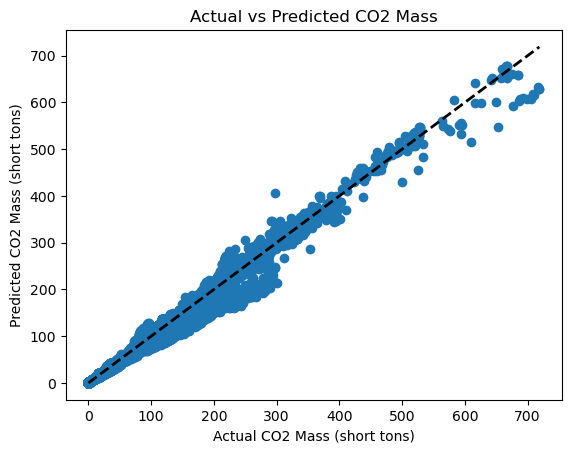

In [ ]:
# model with default parameters (no lags, no unmeasured data, no temps)

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)


y_pred = xgb_default_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual CO2 Mass (short tons)")
plt.ylabel("Predicted CO2 Mass (short tons)")
plt.title("Actual vs Predicted CO2 Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

R^2 Score: 0.9992
Mean Squared Error (MSE): 2.3579
Root Mean Squared Error (RMSE): 1.5355
Normalized RMSE (by std): 0.0277


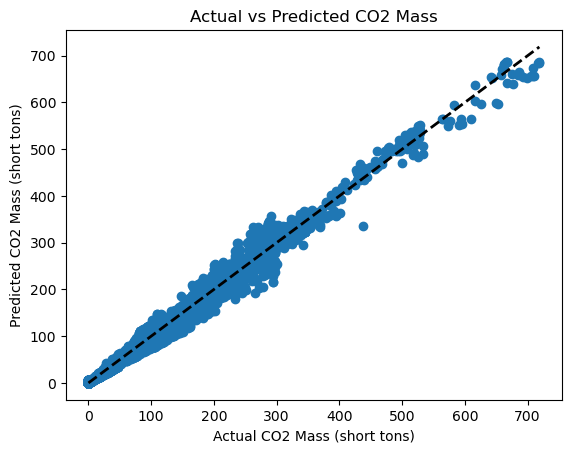

In [ ]:
# model with default parameters (no lags, no unmeasured data, with temps)

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

# dump model
xgb_default_model.save_model("NY/Hourly/Concatted File/Modeling/XGB/CO2/Trained Models/xgb_default_model_ny_no_lags_no_unmeasured.json")

y_pred = xgb_default_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual CO2 Mass (short tons)")
plt.ylabel("Predicted CO2 Mass (short tons)")
plt.title("Actual vs Predicted CO2 Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

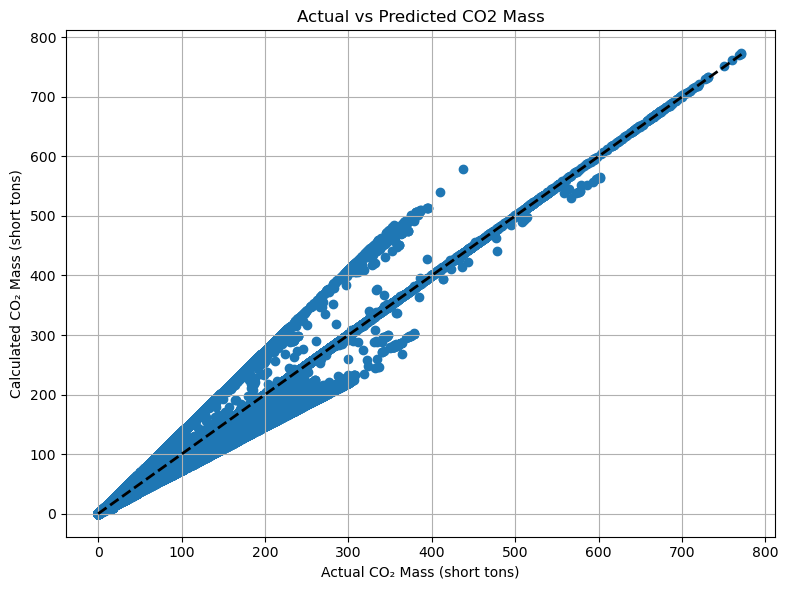

R² Score: 0.9956
Mean Squared Error (MSE): 12.6540
Root Mean Squared Error (RMSE): 3.5572
Normalized RMSE (by std): 0.0662


In [ ]:
# calc co2 alone (formula from Part 75 Appendix G)
# only gas- and oil-fired units

# Define actual and predicted values
y_actual = campd_df["CO2 Mass (short tons)"]
y_predicted = campd_df["Calc CO2 emission rate (tons)"]

# Drop rows with NaNs in either column
valid_mask = y_actual.notna() & y_predicted.notna()
y_actual_clean = y_actual[valid_mask]
y_predicted_clean = y_predicted[valid_mask]

# Scatter plot: Actual vs Predicted CO2 Mass
plt.figure(figsize=(8, 6))
plt.scatter(y_actual_clean, y_predicted_clean)
plt.xlabel("Actual CO₂ Mass (short tons)")
plt.ylabel("Calculated CO₂ Mass (short tons)")
plt.title("Actual vs Predicted CO2 Mass")

# 1:1 reference line
min_val = min(y_actual_clean.min(), y_predicted_clean.min())
max_val = max(y_actual_clean.max(), y_predicted_clean.max())
plt.plot([min_val, max_val], [min_val, max_val], 'k--', lw=2)

plt.grid(True)
plt.tight_layout()
plt.show()

# Evaluate performance
r2 = r2_score(y_actual_clean, y_predicted_clean)
mse = mean_squared_error(y_actual_clean, y_predicted_clean)
rmse = np.sqrt(mse)
nrmse = rmse / np.std(y_actual_clean)

print(f"R² Score: {r2:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Normalized RMSE (by std): {nrmse:.4f}")

# some errors are introduced due to a missing flag of which fuel type is being used
# some units may switch between gas and oil

R^2 Score: 0.9993
Mean Squared Error (MSE): 2.1616
Root Mean Squared Error (RMSE): 1.4703
Normalized RMSE (by std): 0.0265


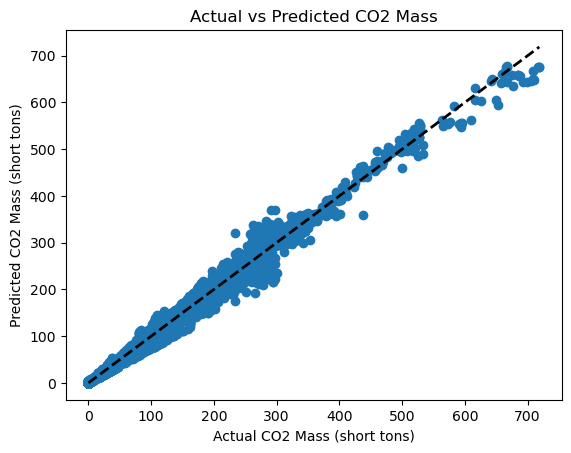

In [22]:
# model with default parameters (no lags, no unmeasured data, with calc co2)

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

# dump model
#xgb_default_model.save_model("NY/Hourly/Concatted File/Modeling/XGB/CO2/Trained Models/xgb_default_model_ny_with_lags_no_unmeasured.json")

y_pred = xgb_default_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual CO2 Mass (short tons)")
plt.ylabel("Predicted CO2 Mass (short tons)")
plt.title("Actual vs Predicted CO2 Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

R^2 Score: 0.9995
Mean Squared Error (MSE): 1.3859
Root Mean Squared Error (RMSE): 1.1772
Normalized RMSE (by std): 0.0212


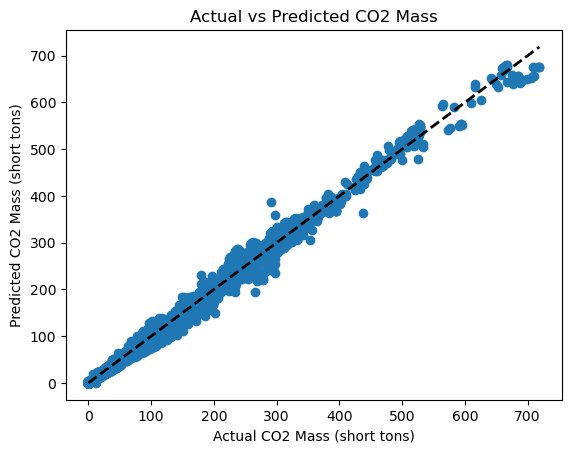

In [ ]:
# model with default parameters (with lags, no unmeasured data, with calc co2)

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

# dump model
#xgb_default_model.save_model("NY/Hourly/Concatted File/Modeling/XGB/CO2/Trained Models/xgb_default_model_ny_with_lags_no_unmeasured.json")

y_pred = xgb_default_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual CO2 Mass (short tons)")
plt.ylabel("Predicted CO2 Mass (short tons)")
plt.title("Actual vs Predicted CO2 Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

R^2 Score: 0.9995
Mean Squared Error (MSE): 1.4329
Root Mean Squared Error (RMSE): 1.1970
Normalized RMSE (by std): 0.0216


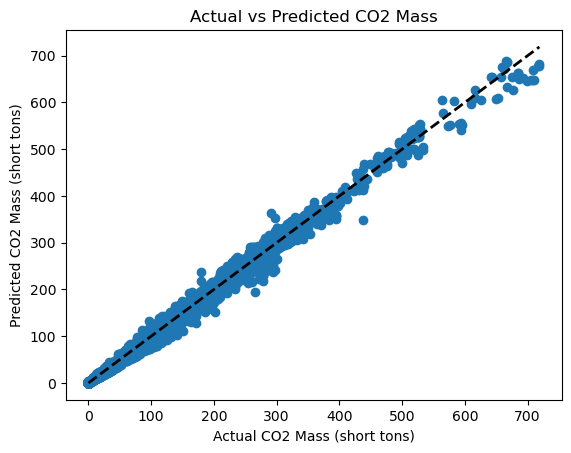

In [ ]:
# model with default parameters (with lags, no unmeasured data)

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

# dump model
xgb_default_model.save_model("NY/Hourly/Concatted File/Modeling/XGB/CO2/Trained Models/xgb_default_model_ny_with_lags_no_unmeasured.json")

y_pred = xgb_default_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual CO2 Mass (short tons)")
plt.ylabel("Predicted CO2 Mass (short tons)")
plt.title("Actual vs Predicted CO2 Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

In [30]:
mask_below_500 = y_test < 500
rmse_below_500 = np.sqrt(mean_squared_error(y_test[mask_below_500], y_pred[mask_below_500]))

mask_above_500 = y_test >= 500
rmse_above_500 = np.sqrt(mean_squared_error(y_test[mask_above_500], y_pred[mask_above_500]))

print(f"RMSE for CO2 Mass below 500 lbs: {rmse_below_500:.4f}")
print(f"RMSE for CO2 Mass above 500 lbs: {rmse_above_500:.4f}")

RMSE for CO2 Mass below 500 lbs: 1.1385
RMSE for CO2 Mass above 500 lbs: 20.0262


<h6>HPO - Optuna Trials</h6>

In [ ]:
# default parameters for comparison
# optimization has bias variance tradeoff, see documentation: https://xgboost.readthedocs.io/en/stable/tutorials/param_tuning.html

default_params = {
    # "n_estimators": 100, # number of trees (larger value, more likely to overfit)
    # "max_depth":  6, # max depth of a tree (larger value, more complex, more likely to overfit)
    # "learning_rate": 0.5, # step size shrinkage eta (lower value, more conservative)
    # "subsample": 1, # random subset size of data to use for each tree (lower value, more conservative)
    # "colsample_bytree": 1, # random subset of features to consider for each tree (lower value, more conservative)
    # "gamma": 0, # min loss reduction to make a split (larger value, more conservative)
    # "reg_alpha": 0, # L1 regularization on weights (larger value, more conservative)
    # "reg_lambda": 1, # L2 regularization on weights (larger value, more conservative)
    # "min_child_weight": 1, # min sum of instance weight (hessian) needed in a child (larger value, more conservative)
    # "tree_method": "auto" # automatically chooses exact or approximation method based on data size

    # needed params for xgb.train
    "objective": "reg:squarederror",
    'eval_metric': 'rmse',
    "tree_method": "hist", # approximation (faster, but not exact, should change on final run)
    "device": "cuda", # use gpu (if unavailable, will use cpu)
    'seed': 42 # like random_state, but for xgb.train
}

In [ ]:
# objective function for optuna
def objective(trial):
    print(f"Starting trial {trial.number}")

    params = {
        "max_depth": trial.suggest_int("max_depth", 4, 25),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.25),
        "subsample": trial.suggest_float("subsample", 0.3, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.7, 1.0),
        "gamma": trial.suggest_float("gamma", 0, 0.5),
        "reg_alpha": trial.suggest_float("reg_alpha", 0, 0.2),
        "reg_lambda": trial.suggest_float("reg_lambda", 0.1, 6.0),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 15),
        "tree_method": "hist",
        "objective": "reg:squarederror",
        "eval_metric": "rmse",
        #"device": "cuda"  # or "cpu"
    }

    tscv = TimeSeriesSplit(n_splits=5)
    rmse_folds = []
    best_iterations = []

    for fold, (train_idx, test_idx) in enumerate(tscv.split(X_train)):
        current_X_train, current_X_test = X_train.iloc[train_idx], X_train.iloc[test_idx]
        current_y_train, current_y_test = y_train.iloc[train_idx], y_train.iloc[test_idx]

        current_dtrain = xgb.DMatrix(current_X_train, label=current_y_train)
        current_dtest = xgb.DMatrix(current_X_test, label=current_y_test)

        evals_result = {}
        model = xgb.train(
            params,
            current_dtrain,
            num_boost_round=1000,
            evals=[(current_dtest, "validation")],
            early_stopping_rounds=20,
            verbose_eval=False, # prevents printing at each boosting stage
            evals_result=evals_result
        )

        best_iterations.append(model.best_iteration)
        # Get last RMSE from evals_result
        fold_rmse = evals_result["validation"]["rmse"][model.best_iteration - 1] # (0-indexed)
        rmse_folds.append(fold_rmse)

        print(f"Fold {fold+1} rmse: {fold_rmse:.4f} best_iteration: {model.best_iteration}")

    avg_rmse = np.mean(rmse_folds)
    avg_best_iter = int(np.mean(best_iterations))

    print(f"Trial {trial.number} avg RMSE: {avg_rmse:.4f}, avg best_iteration: {avg_best_iter}")

    # manually store the avg best boosting rounds and full list of rmse folds (we output the avg rmse separately)
    trial.set_user_attr("best_iteration", avg_best_iter)
    trial.set_user_attr("fold_rmses", rmse_folds)

    return avg_rmse


In [ ]:
study = optuna.create_study(study_name="HPT 22.06.25 18:04", storage="sqlite:///optuna_studies.db", direction="minimize")
study.optimize(objective, n_trials=50) 
print("Best params:", study.best_params)

In [ ]:
study = optuna.load_study(
    study_name="HPT 22.06.25 18:04", 
    storage="sqlite:///optuna_studies.db"
)

# Get the best 5 trials
sorted_trials = sorted(
    [t for t in study.trials if t.value is not None], 
    key=lambda t: t.value
)

for i, trial in enumerate(sorted_trials[:5], 1):
    print(f"\nTrial {i}:")
    print(f"  Value (Objective): {trial.value}")
    print(f"  Number: {trial.number}")
    print(f"  Params:")
    for key, val in trial.params.items():
        print(f"    {key}: {val}")
    print(f"best_iteration: {trial.user_attrs.get("best_iteration")}")

second_best_params = sorted_trials[1]



Trial 1:
  Value (Objective): 9.745089838254874
  Number: 43
  Params:
    max_depth: 14
    learning_rate: 0.01070681077554956
    subsample: 0.318354394879375
    colsample_bytree: 0.777646548524244
    gamma: 0.3607772120989284
    reg_alpha: 0.0108703758177803
    reg_lambda: 0.38740560311398076
    min_child_weight: 7
best_iteration: 570

Trial 2:
  Value (Objective): 9.764771259078591
  Number: 36
  Params:
    max_depth: 14
    learning_rate: 0.028307079329367588
    subsample: 0.5346591526735095
    colsample_bytree: 0.755707012641865
    gamma: 0.32794467494879476
    reg_alpha: 0.03674279467914575
    reg_lambda: 1.067013332785789
    min_child_weight: 15
best_iteration: 243

Trial 3:
  Value (Objective): 9.767127299776904
  Number: 51
  Params:
    max_depth: 14
    learning_rate: 0.010448475834795221
    subsample: 0.47530695004986934
    colsample_bytree: 0.7956950970651904
    gamma: 0.3060105397027625
    reg_alpha: 0.020536194292598522
    reg_lambda: 0.105707880825134

In [23]:
study = optuna.load_study(
    study_name="HPT 22.06.25 18:04", 
    storage="sqlite:///optuna_studies.db"
)

print("Best params:", study.best_params)
print("Best value (RMSE):", study.best_value)
print(study.best_trial.user_attrs.get("best_iteration")) 

# HPO visualizations
fig1 = vis.plot_param_importances(study)
fig2 = vis.plot_optimization_history(study)
fig3 = vis.plot_slice(study)

# update font to Times New Roman
for fig in [fig1, fig2, fig3]:
    fig.update_layout(font=dict(family="Times New Roman", size=14)) 
    fig.show()

Best params: {'max_depth': 14, 'learning_rate': 0.01070681077554956, 'subsample': 0.318354394879375, 'colsample_bytree': 0.777646548524244, 'gamma': 0.3607772120989284, 'reg_alpha': 0.0108703758177803, 'reg_lambda': 0.38740560311398076, 'min_child_weight': 7}
Best value (RMSE): 9.745089838254874
570


<h6>HPO - Model</h6>

In [36]:
# best params found
hpo_params = {
    **study.best_params,
    #"n_estimators": study.best_trial.user_attrs.get("best_iteration"),
    "tree_method": "hist",
    #"device": "cuda", # use gpu or cpu
    "objective": "reg:squarederror",
    'eval_metric': 'rmse',
    "seed": 42
}

In [ ]:
# second best params found
second_best_hpo_params = {
    **second_best_params.params,
    #"n_estimators": study.best_trial.user_attrs.get("best_iteration"),
    "tree_method": "hist",
    #"device": "cuda", # use gpu or cpu
    "objective": "reg:squarederror",
    'eval_metric': 'rmse',
    "seed": 42
}


In [ ]:
default_params = {
    "n_estimators": 100, # number of trees (larger value, more likely to overfit)
    "max_depth":  6, # max depth of a tree (larger value, more complex, more likely to overfit)
    "learning_rate": 0.5, # step size shrinkage eta (lower value, more conservative)
    "subsample": 1, # random subset size of data to use for each tree (lower value, more conservative)
    "colsample_bytree": 1, # random subset of features to consider for each tree (lower value, more conservative)
    "gamma": 0, # min loss reduction to make a split (larger value, more conservative)
    "reg_alpha": 0, # L1 regularization on weights (larger value, more conservative)
    "reg_lambda": 1, # L2 regularization on weights (larger value, more conservative)
    "min_child_weight": 1, # min sum of instance weight (hessian) needed in a child (larger value, more conservative)
    "tree_method": "auto" # automatically chooses exact or approximation method based on data size
}

R^2 Score: 0.9833
Mean Squared Error (MSE): 61.3581
Root Mean Squared Error (RMSE): 7.8331


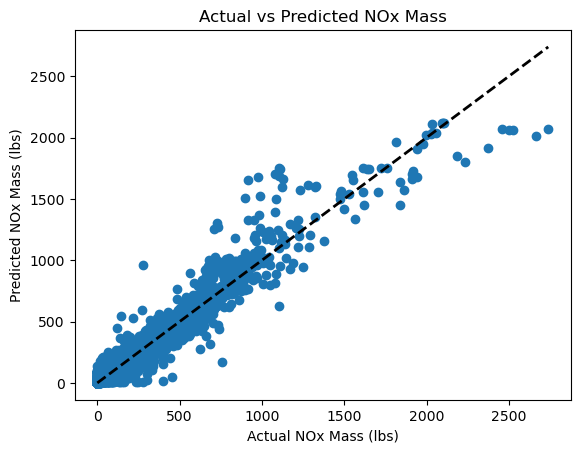

In [ ]:
# model with second best (less boost rounds) hpo parameters (with lags, no unmeasured data)

xgb_hpo_model = xgb.train(params=second_best_hpo_params, dtrain=dtrain, num_boost_round=254)

# dump model
xgb_hpo_model.save_model("NY/Hourly/Concatted File/Modeling/XGB/CO2/Trained Models/xgb_hpo_model_ny_with_lags_no_unmeasured.json")

y_pred = xgb_hpo_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual CO2 Mass (short tons)")
plt.ylabel("Predicted CO2 Mass (short tons)")
plt.title("Actual vs Predicted CO2 Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

R^2 Score: 0.9834
Mean Squared Error (MSE): 60.9311
Root Mean Squared Error (RMSE): 7.8058


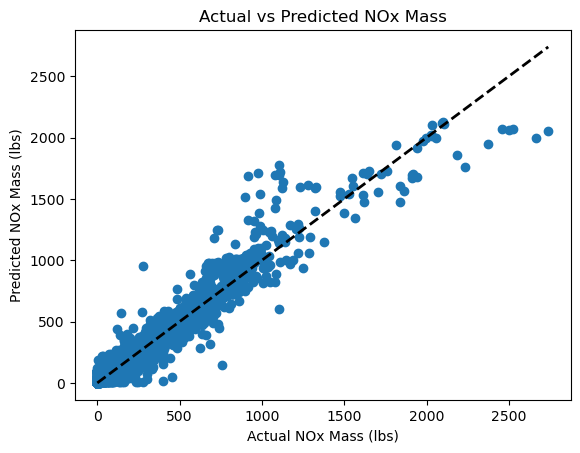

In [ ]:
# model with best hpo parameters (no unmeasured data)

xgb_hpo_model = xgb.train(params=hpo_params, dtrain=dtrain, num_boost_round=570)

# dump model
#xgb_hpo_model.save_model("NY/Hourly/Concatted File/Modeling/XGB/CO2/Trained/Models/xgb_hpo_model_ny_with_lags_no_unmeasured.json")

y_pred = xgb_hpo_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual CO2 Mass (short tons)")
plt.ylabel("Predicted CO2 Mass (short tons)")
plt.title("Actual vs Predicted CO2 Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

<h2>Interpretability</h2>

<h5>Read-in Models</h5>

In [70]:
# load saved models
xgb_default_model_with_lags = xgb.Booster()
xgb_default_model_with_lags.load_model("NY/Hourly/Concatted File/Modeling/XGB/CO2/Trained Models/xgb_default_model_ny_with_lags_no_unmeasured.json")

xgb_default_model_no_lags = xgb.Booster()
xgb_default_model_no_lags.load_model("NY/Hourly/Concatted File/Modeling/XGB/CO2/Trained Models/xgb_default_model_ny_no_lags_no_unmeasured.json")

rf_default_model_no_lags = joblib.load("NY/Hourly/Concatted File/Modeling/RF/CO2/Trained Models/rf_default_model_ny_no_lags_no_unmeasured_with_temps.json")

rf_default_model_with_lags = joblib.load("NY/Hourly/Concatted File/Modeling/RF/CO2/Trained Models/rf_default_model_ny_with_lags_no_unmeasured_with_temps.json")



In [ ]:
xgb_hpo_model = xgb.Booster()
xgb_hpo_model.load_model("NY/Hourly/Concatted File/Modeling/XGB/CO2/Trained Models/xgb_hpo_model_ny_with_lags_no_unmeasured.json")

<h3>RF (model-specific)</h3>

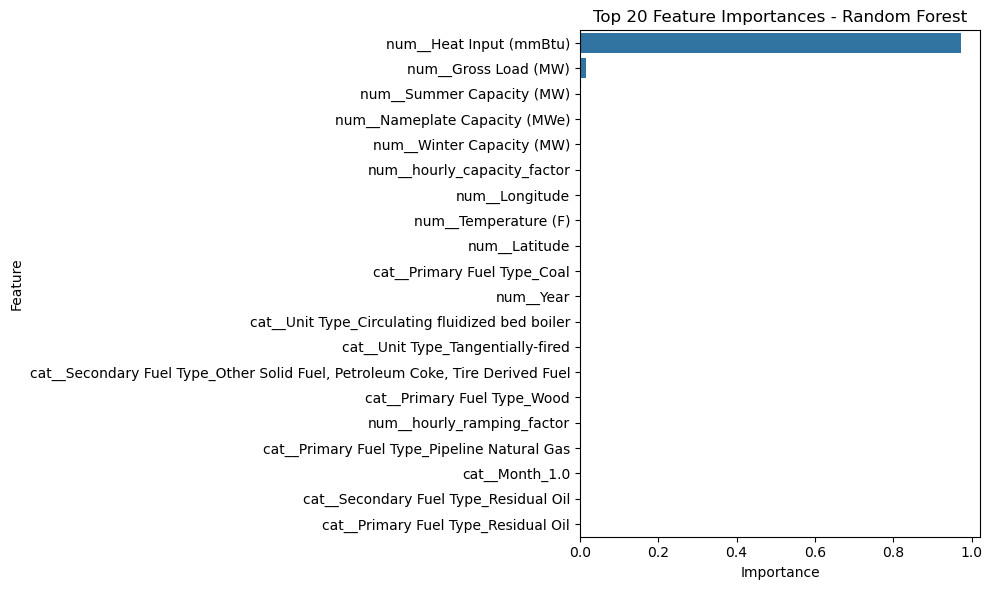

In [78]:
# for default rf model no lags, no unmeasured data, with temps

importances = rf_default_model_no_lags.feature_importances_

# Create a DataFrame for better handling
feat_imp_df = pd.DataFrame({
    'Feature': X_sampled.columns,
    'Importance': importances
})

# Sort by importance
feat_imp_df = feat_imp_df.sort_values(by='Importance', ascending=False)

# uses MDI (Mean Decrease in Impurity)
plt.figure(figsize=(10, 6))
sns.barplot(data=feat_imp_df.head(20), x='Importance', y='Feature')
plt.title('Top 20 Feature Importances - Random Forest')
plt.tight_layout()
plt.show()


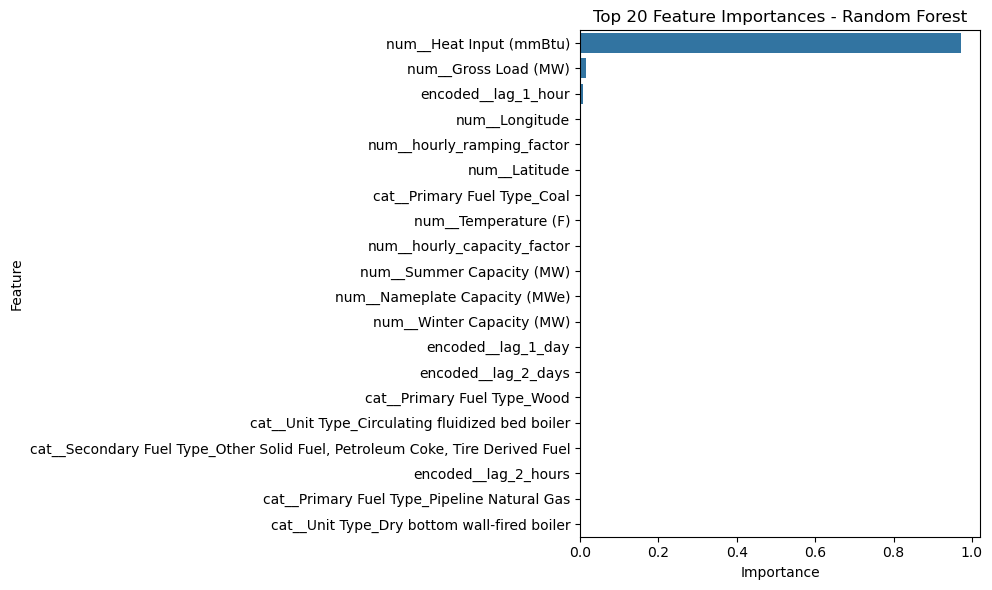

In [81]:
# for default rf model with lags, no unmeasured data, with temps

importances = rf_default_model_with_lags.feature_importances_

# Create a DataFrame for better handling
feat_imp_df = pd.DataFrame({
    'Feature': X_sampled.columns,
    'Importance': importances
})

# Sort by importance
feat_imp_df = feat_imp_df.sort_values(by='Importance', ascending=False)

# uses MDI (Mean Decrease in Impurity)
plt.figure(figsize=(10, 6))
sns.barplot(data=feat_imp_df.head(20), x='Importance', y='Feature')
plt.title('Top 20 Feature Importances - Random Forest')
plt.tight_layout()
plt.show()


<h3>XGB (model-specific)</h3>

<h5>Default Params</h5>

<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

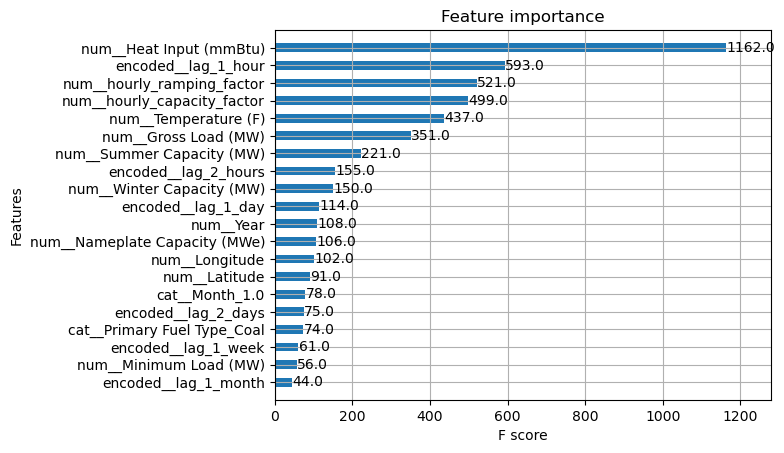

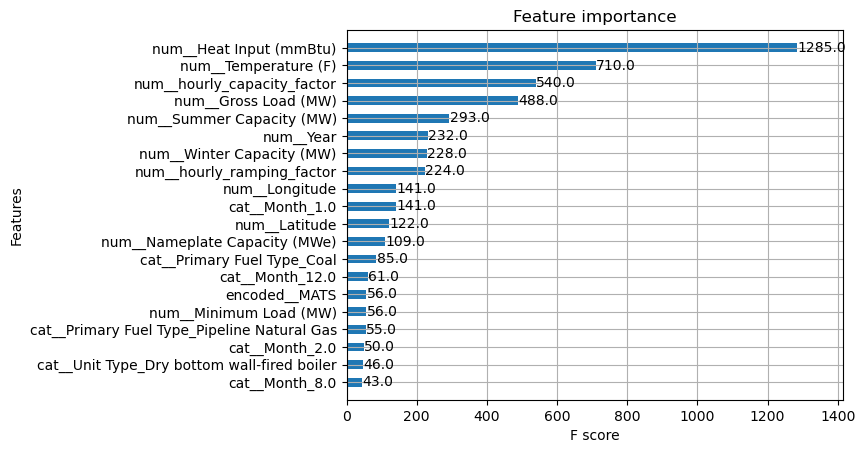

In [82]:
# use weight for feature importance (how often the feature is used in splits)
plot_importance(
    xgb_default_model_with_lags, 
    importance_type='weight',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

plot_importance(
    xgb_default_model_no_lags, 
    importance_type='weight',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

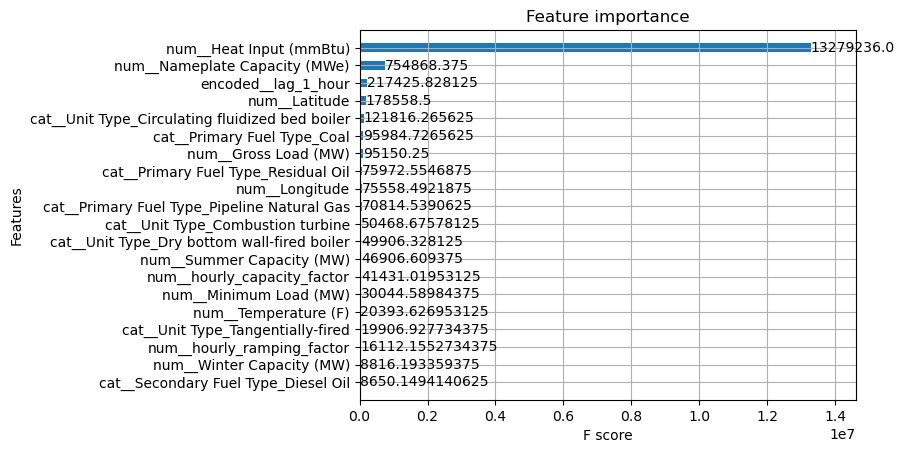

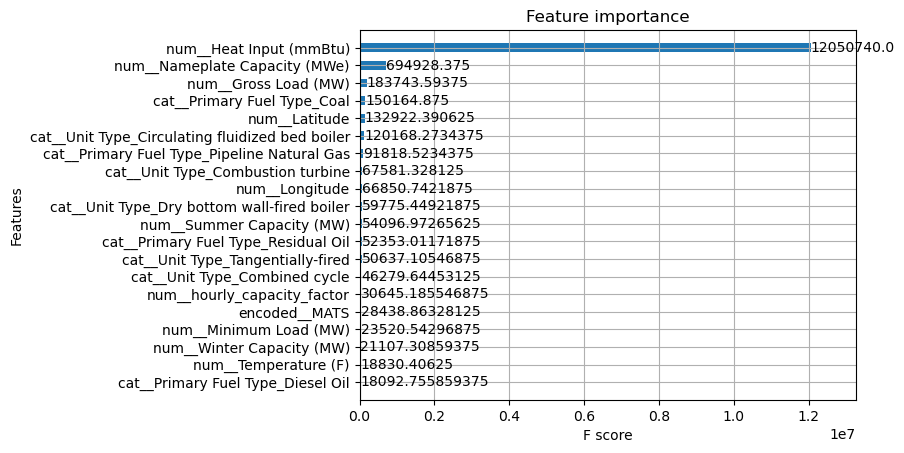

In [83]:
# use gain for feature importance (Average improvement in loss from splits involving that feature)
plot_importance(
    xgb_default_model_with_lags, 
    importance_type='gain',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

plot_importance(
    xgb_default_model_no_lags, 
    importance_type='gain',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

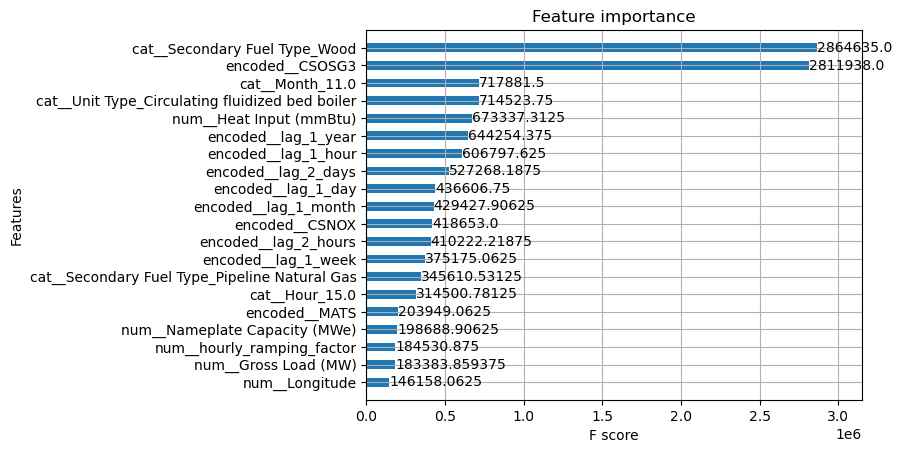

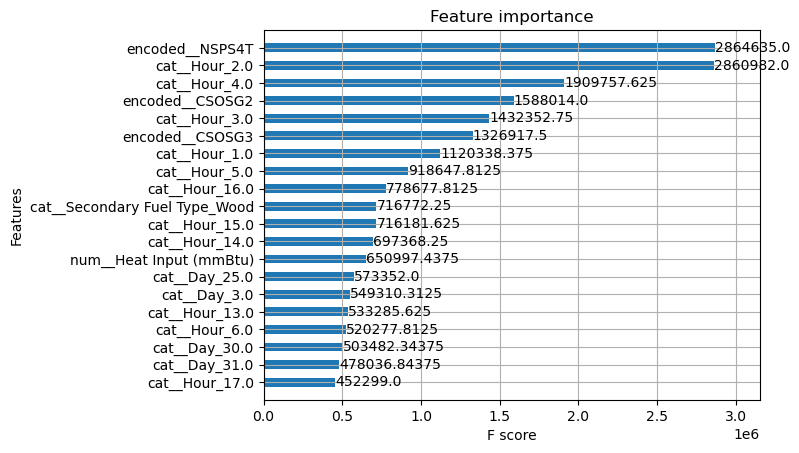

In [84]:
# use cover for feature importance (how many observations are affected by the feature)
plot_importance(
    xgb_default_model_with_lags, 
    importance_type='cover',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

plot_importance(
    xgb_default_model_no_lags, 
    importance_type='cover',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

<h5>HPO Params</h5>

In [ ]:
# use weight for feature importance (how often the feature is used in splits)
plot_importance(
    xgb_hpo_model, 
    importance_type='weight',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

In [ ]:
# use gain for feature importance (Average improvement in loss from splits involving that feature)
plot_importance(
    xgb_hpo_model, 
    importance_type='gain',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

In [ ]:
# use cover for feature importance (how many observations are affected by the feature)
plot_importance(
    xgb_hpo_model, 
    importance_type='cover', 
    max_num_features=20,      
    height=0.5,
    show_values=True,
    grid=True
)

<h3>Partial Dependence Plots</h3>

<h3>Permutation Importance</h3>

<h4>Default Params</h4>

In [85]:
regressor = XGBRegressor()
regressor._Booster = xgb_default_model_no_lags

In [89]:
result = permutation_importance(regressor, X_test, y_test, n_repeats=5, random_state=42, scoring='neg_mean_squared_error')

importance_df = pd.DataFrame({
    'feature': X_test.columns,
    'importance_mean': result.importances_mean,
    'importance_std': result.importances_std
}).sort_values(by='importance_mean', ascending=False)

display(importance_df)


,feature,importance_mean,importance_std
93,num__Heat Input (mmBtu),6828.015463,8.444190
94,num__Latitude,58.285907,0.790893
96,num__Nameplate Capacity (MWe),32.315474,0.742057
92,num__Gross Load (MW),24.940495,0.135669
97,num__hourly_capacity_factor,21.247558,0.499510
...,...,...,...
9,cat__Month_10.0,-0.009148,0.001705
5,cat__Month_6.0,-0.033172,0.004364
62,cat__Day_27.0,-0.039583,0.006470
57,cat__Day_22.0,-0.046622,0.000969


<h4>Ungrouped</h4>

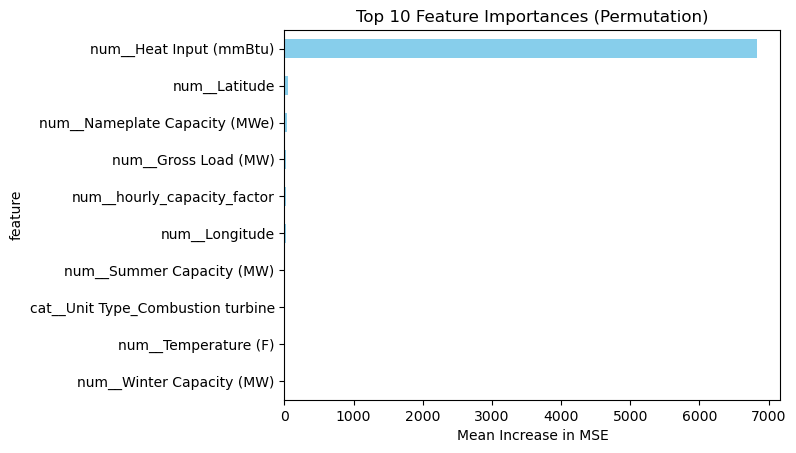

In [90]:
importance_df.head(10).plot.barh(
    x='feature', 
    y='importance_mean', 
    legend=False,
    color='skyblue'
)

plt.xlabel('Mean Increase in MSE')
plt.title('Top 10 Feature Importances (Permutation)')
plt.gca().invert_yaxis()  # get the most important on top
plt.show()


In [26]:
# num features
num_features = ['num__Gross Load (MW)',
                 'num__Heat Input (mmBtu)', 
                 'num__Latitude', 
                 'num__Longitude', 
                 'num__Nameplate Capacity (MWe)',
                   'num__hourly_capacity_factor', 
                   'num__hourly_ramping_factor', 
                   'num__Summer Capacity (MW)', 
                   'num__Winter Capacity (MW)', 
                   'num__Minimum Load (MW)'] # we ignore day, hour, month, year

In [ ]:
# group features systematically (cluster on correlation)

X_subset = X_test[num_features]
X_subset = X_subset.dropna()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 8))

# Compute Spearman correlation matrix on selected features
corr = spearmanr(X_subset).correlation

# Make symmetric and fill diagonal with 1s
corr = (corr + corr.T) / 2
np.fill_diagonal(corr, 1)

# Convert correlation to distance matrix for clustering
distance_matrix = 1 - np.abs(corr)
dist_linkage = hierarchy.ward(squareform(distance_matrix))

# Plot dendrogram
dendro = hierarchy.dendrogram(
    dist_linkage, labels=X_subset.columns.to_list(), ax=ax1, leaf_rotation=90
)
dendro_idx = np.arange(len(dendro["ivl"]))

# Plot reordered heatmap of correlations
im = ax2.imshow(corr[dendro["leaves"], :][:, dendro["leaves"]],
                cmap='RdBu_r', vmin=-1, vmax=1)
ax2.set_xticks(dendro_idx)
ax2.set_yticks(dendro_idx)
ax2.set_xticklabels(dendro["ivl"], rotation=90)
ax2.set_yticklabels(dendro["ivl"])

# Add colorbar
fig.colorbar(im, ax=ax2, fraction=0.046, pad=0.04)

ax1.set_title("Feature Clustering Dendrogram")
ax2.set_title("Spearman Correlation Heatmap")

plt.tight_layout()
plt.show()

# distance here is calculated as 1 - Spearman correlation coefficient


In [ ]:
# select only one feature per group of features with distance <0.2 -> Heat Input, Nameplate Capacity (MWe)

In [29]:
X_train = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/X_train_processed", dtype=campd_type_dict)
X_test = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/X_test_processed", dtype=campd_type_dict)
y_train = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/y_train")
y_test = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/y_test")

In [30]:
# group features below threshold of 0.2 (over 80% correlation) and retrain

X_train = X_train.drop(columns=["num__hourly_capacity_factor", "num__Gross Load (MW)", "num__Summer Capacity (MW)",
                "num__Winter Capacity (MW)"])
X_test = X_test.drop(columns=["num__hourly_capacity_factor", "num__Gross Load (MW)", "num__Summer Capacity (MW)",
                "num__Winter Capacity (MW)"])

# Convert to DMatrix for XGBoost
dtrain = xgb.DMatrix(X_train, label=y_train) 
dtest = xgb.DMatrix(X_test, label=y_test)

In [ ]:
# Model with default parameters and grouped features (with lags, no unmeasured data)

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

y_pred = xgb_default_model.predict(dtest)
y_test = dtest.get_label()
print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual CO2 Mass (short tons)")
plt.ylabel("Predicted CO2 Mass (short tons)")
plt.title("Actual vs Predicted CO2 Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

In [34]:
regressor = XGBRegressor()
regressor._Booster = xgb_default_model

In [35]:
result = permutation_importance(regressor, X_test, y_test, n_repeats=5, random_state=42, scoring='neg_mean_squared_error')

In [ ]:
importance_df = pd.DataFrame({
    'feature': X_test.columns,
    'importance_mean': result.importances_mean,
    'importance_std': result.importances_std
}).sort_values(by='importance_mean', ascending=False)

print(importance_df)


<h4>Grouped</h4>

In [ ]:
importance_df.head(20).plot.barh(
    x='feature', 
    y='importance_mean', 
    legend=False,
    color='skyblue'
)

plt.xlabel('Mean Increase in MSE (neg_mean_squared_error)')
plt.title('Top 10 Feature Importances (Permutation)')
plt.gca().invert_yaxis()  # get the most important on top
plt.show()


<h3>SHAP</h3>

<h4>Using Default Params</h4>

<h5>No Lags</h5>

In [91]:
explainer = shap.TreeExplainer(xgb_default_model_no_lags)

In [92]:
shap_values = explainer(X_test, approximate=False)

In [93]:
joblib.dump(shap_values, "NY/Hourly/Concatted File/Modeling/XGB/CO2/Trained Models/shap_values_xgb_default_model_ny_no_lags_no_unmeasured.pkl")

['NY/Hourly/Concatted File/Modeling/XGB/CO2/Trained Models/shap_values_xgb_default_model_ny_no_lags_no_unmeasured.pkl']

In [ ]:
shap_values = joblib.load("NY/Hourly/Concatted File/Modeling/XGB/CO2/Trained Models/shap_values_xgb_default_model_ny_no_lags_no_unmeasured.pkl")

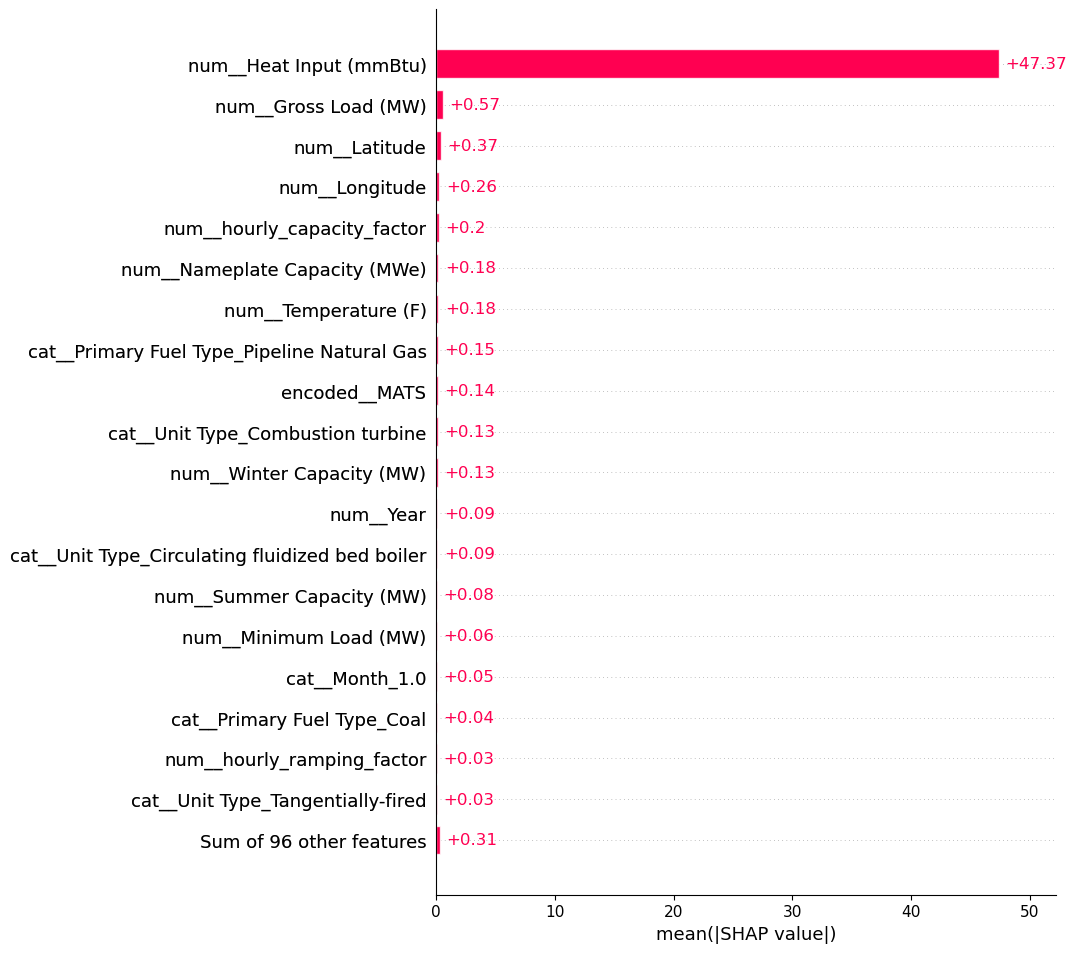

In [94]:
shap.plots.bar(shap_values, max_display=20)

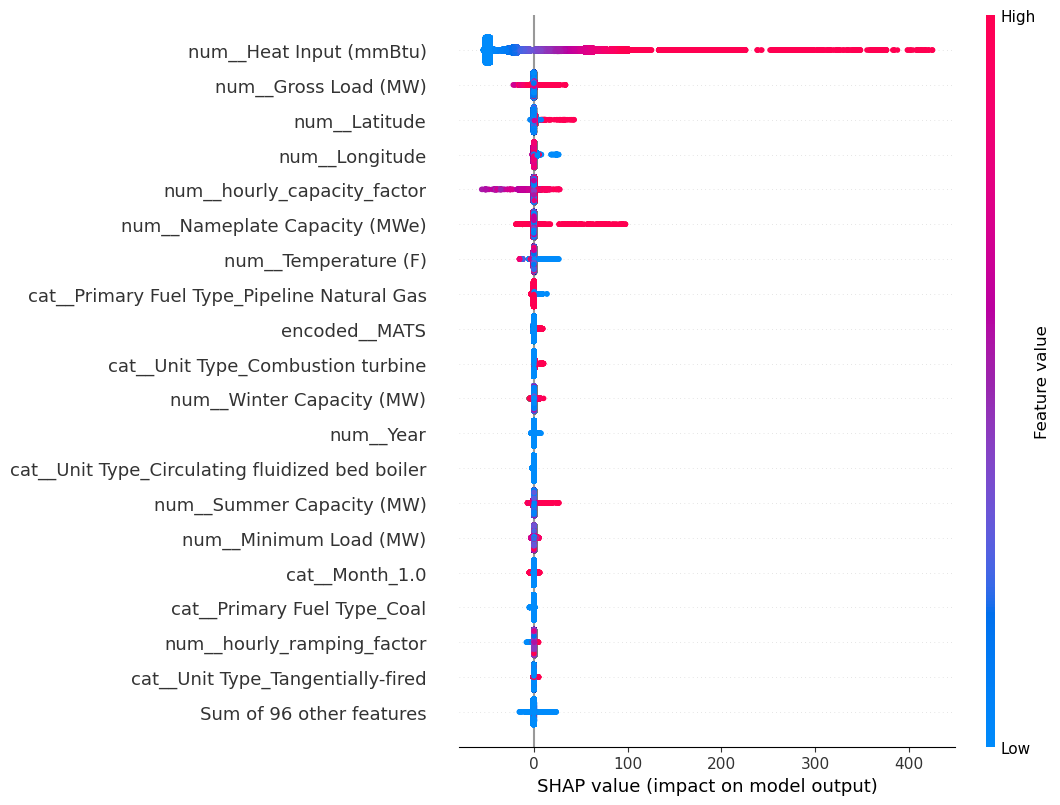

In [95]:
shap.plots.beeswarm(shap_values, max_display=20)